## Feature Space FS6: Agglomerative Hierarchical Clustering on 14 Concentric-Ring Features

> **Core Methodological Rule: Algorithm Autonomy in Candidate Selection**
> We do NOT carry forward candidate choices or assumptions from prior algorithms ($K$-Means or GMM).
> To prevent cognitive bias, each clustering paradigm must independently discover its optimal candidate configurations strictly through its own mathematical mechanics and evaluation diagnostics. For Hierarchical Clustering, candidates are determined directly by **dendrogram merge height leaps ($\Delta h$)**, **Cophenetic distance preservation**, **Davies-Bouldin minimums**, and **ARI/NMI peaks**.

**Notebook Goals**:
1. **Data Loading & Preparation**: Leakage-free extraction of standardized concentric ring features (`data/contour_concentric_rings/`).
2. **Linkage Method & Distance Metric Benchmarking**:
   - Evaluate linkage criteria: **Ward** (minimum variance), **Average** (UPGMA), **Complete** (maximum distance), and **Single** (minimum distance / nearest neighbor).
   - Evaluate distance metrics: **Euclidean ($L_2$)**, **Cosine** (angular profile), and **Manhattan / Cityblock ($L_1$)**.
   - Quantify tree fidelity using the **Cophenetic Correlation Coefficient** and compare against **Adjusted Rand Index (ARI)** and **Silhouette Score**.
   - Diagnose the "chaining effect" in Single and Average linkage on continuous manifold spaces.
3. **Dendrogram Architecture & Cut-off Threshold Analysis**:
   - Construct full hierarchical linkage matrix ($Z$) on $N=10,000$ representative samples.
   - Visualize truncated dendrograms (`truncate_mode='lastp'`) with annotated cut-off distance thresholds.
   - Analyze acceleration and distance leaps in merge heights to identify natural structural levels.
4. **Hierarchical Candidate Selection ($k \in \{5, 7, 10, 11\}$)**:
   - $k=5$: Major macro-level tree leap ($\Delta h = 37.44$) & global minimum Davies-Bouldin index ($1.7831$).
   - $k=7$: Intermediate branch inflection point ($\Delta h = 21.94$).
   - $k=10$: Class-level tree leap ($\Delta h = 12.22$) corresponding to digit classes.
   - $k=11$: Global peak of Adjusted Rand Index ($\text{ARI} = 0.2522$) and Normalized Mutual Information ($\text{NMI} = 0.3293$).
5. **Dimensionality Reduction & Manifold Visualizations**:
   - 2D Projections (PCA, t-SNE, UMAP).
   - Interactive 3D WebGL PCA projection with restyle dropdowns.
   - Contingency matrices (sample counts and row-normalized percentage heatmaps).
6. **Centroid Radial Profiles & Prototype Visualizations**:
   - Radial profiles of cluster centroids across the 14 concentric ring shells.
   - Top 5 prototype digits closest to each hierarchical cluster center (Raw Grayscale + 1-Pixel Contours).
7. **Cross-Algorithm Triangulation**:
   - Unbiased comparative synthesis across **$K$-Means**, **Gaussian Mixture Models (GMM)**, and **Agglomerative Hierarchical Clustering**.

In [17]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import umap
from mpl_toolkits.mplot3d import Axes3D
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    homogeneity_completeness_v_measure,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.metrics.cluster import contingency_matrix

In [18]:
# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment configured: Libraries loaded successfully.")

Environment configured: Libraries loaded successfully.


---
### 1. Data Loading & Preparation

We load the standardized concentric ring features from `data/contour_concentric_rings/`:
- `train_scaled.csv`: Standardized concentric ring features (162,000 samples).
- `val_scaled.csv`: Standardized validation features (6,000 samples).
- `images_train.npz`: Compressed archive of 28x28 grayscale digits and binary contours.

> **Data Preparation Rule**:
> For clustering, we filter to the unaugmented training subset (`is_augmented == 0`, $N=54,000$).
> Agglomerative hierarchical clustering computes an $O(N^2)$ distance matrix. For hyperparameter and linkage evaluation, we utilize an identically seeded representative subsample of $N=10,000$ digits.

In [19]:
# 1. Resolve Project Root cleanly
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parents[2] if NOTEBOOK_DIR.name == "clustering" else (
    NOTEBOOK_DIR.parents[1] if NOTEBOOK_DIR.name == "FS6" else NOTEBOOK_DIR
)
DATA_DIR = PROJECT_ROOT / "data" / "contour_concentric_rings"
RESULTS_DIR = PROJECT_ROOT / "results" / "FS6" / "clustering" / "3_agglomerative_hierarchical_clustering"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT.resolve()}")
print(f"Data Dir:     {DATA_DIR.resolve()}")
print(f"Results Dir:  {RESULTS_DIR.resolve()}")

# 2. Load standardized feature tables
train_df = pd.read_csv(DATA_DIR / "train_scaled.csv")
val_df = pd.read_csv(DATA_DIR / "val_scaled.csv")

# 3. Filter to the contoured, unaugmented training digits (is_augmented == 0, N=54,000)
orig_train_df = train_df[train_df["is_augmented"] == 0].reset_index(drop=True)

FEATURE_COLS = [f"ring_{k:02d}" for k in range(14)]

X_train = orig_train_df[FEATURE_COLS].to_numpy(dtype=np.float64)
y_train = orig_train_df["label"].to_numpy(dtype=np.int64)

X_val = val_df[FEATURE_COLS].to_numpy(dtype=np.float64)
y_val = val_df["label"].to_numpy(dtype=np.int64)

# 4. Load both raw grayscale digits and binary contour images from the compressed archive
images_npz = np.load(DATA_DIR / "images_train.npz")
orig_mask = (images_npz["is_augmented"] == 0)
raw_images = images_npz["raw"][orig_mask]          # (54000, 28, 28) uint8 grayscale
contour_images = images_npz["contour"][orig_mask]  # (54000, 28, 28) uint8 binary {0, 1}

print(f"Loaded X_train shape: {X_train.shape} (54,000 unaugmented contoured samples, 14 ring features)")
print(f"Loaded y_train shape: {y_train.shape}")
print(f"Loaded X_val shape:   {X_val.shape} (6,000 validation samples, 14 ring features)")
print(f"Loaded raw images:    {raw_images.shape}")
print(f"Loaded contour images:{contour_images.shape}")

Project Root: D:\Dev\Python\num-classify
Data Dir:     D:\Dev\Python\num-classify\data\contour_concentric_rings
Results Dir:  D:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering
Loaded X_train shape: (54000, 14) (54,000 unaugmented contoured samples, 14 ring features)
Loaded y_train shape: (54000,)
Loaded X_val shape:   (6000, 14) (6,000 validation samples, 14 ring features)
Loaded raw images:    (54000, 28, 28)
Loaded contour images:(54000, 28, 28)


---
### 2. Linkage Methods & Distance Metrics Benchmark

Agglomerative clustering iteratively merges the pair of clusters with the smallest pairwise distance. The definition of inter-cluster distance is governed by the **linkage criterion**:

1. **Ward's Linkage**:
   $$\Delta \text{ESS}_{AB} = \frac{n_A n_B}{n_A + n_B} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|^2$$
   Minimizes the total within-cluster variance at each merge step. Requires Euclidean distance. Strictly favors spherical, compact, and balanced clusters.
2. **Average Linkage (UPGMA)**:
   $$D(A, B) = \frac{1}{|A| |B|} \sum_{\mathbf{x} \in A} \sum_{\mathbf{y} \in B} d(\mathbf{x}, \mathbf{y})$$
   Averages pairwise distances between all members. Compromise between single and complete linkage.
3. **Complete Linkage**:
   $$D(A, B) = \max_{\mathbf{x} \in A, \mathbf{y} \in B} d(\mathbf{x}, \mathbf{y})$$
   Minimizes the maximum diameter of merged clusters. Produces compact clusters, but is sensitive to boundary outliers.
4. **Single Linkage**:
   $$D(A, B) = \min_{\mathbf{x} \in A, \mathbf{y} \in B} d(\mathbf{x}, \mathbf{y})$$
   Connects nearest neighbors. Highly prone to the **chaining effect** on continuous manifolds (creating 1 giant cluster and singleton outliers).

#### Cophenetic Correlation Coefficient ($c$):
Measures how faithfully the dendrogram preserves original pairwise distances:
$$c = \frac{\sum_{i<j} (d(i, j) - \bar{d})(t(i, j) - \bar{t})}{\sqrt{\sum_{i<j} (d(i, j) - \bar{d})^2 \sum_{i<j} (t(i, j) - \bar{t})^2}}$$
where $d(i, j)$ is the original distance and $t(i, j)$ is the cophenetic distance (the height in the tree where samples $i$ and $j$ first merge).

Benchmarking Linkage Methods and Distance Metrics on N=5,000...
  ward     | euclidean | Cophenetic=0.3957 | ARI=0.2327 | Sil=0.0895 | MaxCluster=16.0% (4.69s)
  average  | euclidean | Cophenetic=0.6305 | ARI=0.0141 | Sil=0.1030 | MaxCluster=88.2% (4.69s)
  average  | cosine    | Cophenetic=0.5805 | ARI=0.1888 | Sil=0.0069 | MaxCluster=26.0% (3.31s)
  average  | cityblock | Cophenetic=0.6196 | ARI=0.0100 | Sil=0.0694 | MaxCluster=93.1% (2.20s)
  complete | euclidean | Cophenetic=0.5171 | ARI=0.1421 | Sil=0.0550 | MaxCluster=26.4% (2.34s)
  complete | cosine    | Cophenetic=0.4664 | ARI=0.1848 | Sil=0.0598 | MaxCluster=20.4% (2.59s)
  single   | euclidean | Cophenetic=0.4044 | ARI=0.0000 | Sil=0.1206 | MaxCluster=99.8% (2.05s)


,Linkage,Distance Metric,Cophenetic Corr,ARI (k=10),Silhouette,Largest Cluster %,Time (s)
0,ward,euclidean,0.3957,0.2327,0.0895,16.00,4.6913
1,average,euclidean,0.6305,0.0141,0.1030,88.22,4.6873
2,average,cosine,0.5805,0.1888,0.0069,26.02,3.3096
3,average,cityblock,0.6196,0.0100,0.0694,93.06,2.1977
4,complete,euclidean,0.5171,0.1421,0.0550,26.42,2.3436
5,complete,cosine,0.4664,0.1848,0.0598,20.42,2.5874
6,single,euclidean,0.4044,0.0000,0.1206,99.82,2.0475


Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\0_linkage_metric_benchmark.png


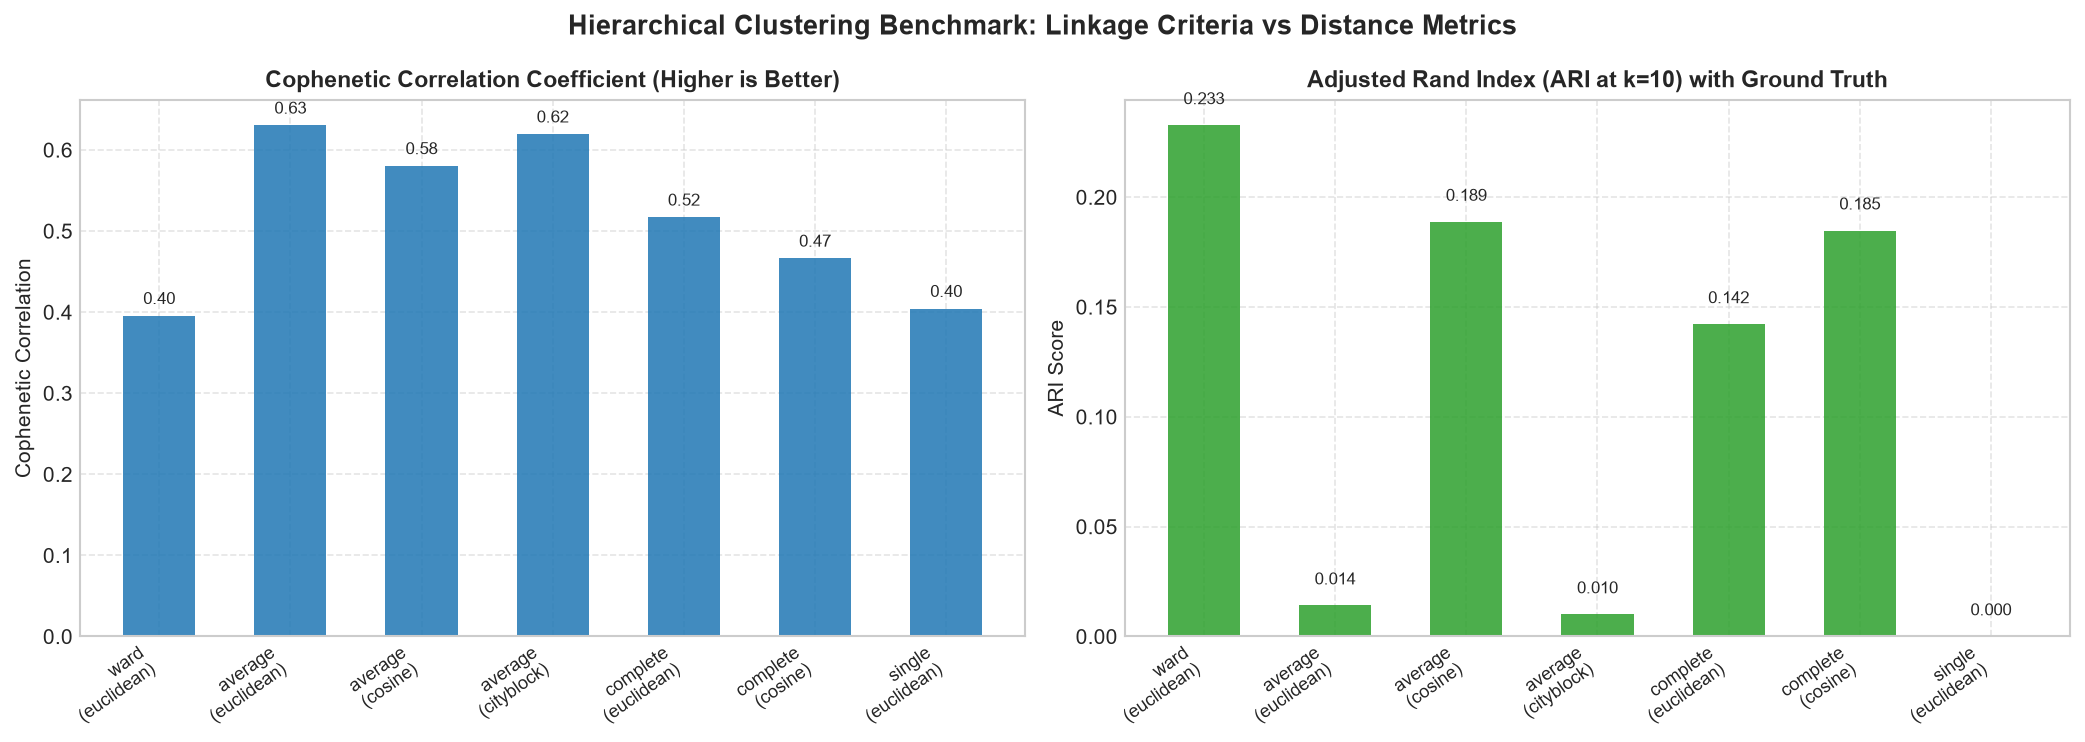

In [20]:
# Subsample 5,000 instances for comprehensive linkage and distance metric benchmarking
N_BENCH = 5000
rng_b = np.random.default_rng(RANDOM_STATE)
bench_idx = rng_b.choice(len(X_train), size=N_BENCH, replace=False)
X_bench = X_train[bench_idx]
y_bench = y_train[bench_idx]

configs = [
    ("ward", "euclidean"),
    ("average", "euclidean"),
    ("average", "cosine"),
    ("average", "cityblock"),
    ("complete", "euclidean"),
    ("complete", "cosine"),
    ("single", "euclidean"),
]

benchmark_results = []
print(f"Benchmarking Linkage Methods and Distance Metrics on N={N_BENCH:,}...")

for method, metric in configs:
    t0 = time.time()
    if method == "ward":
        Z_bench = linkage(X_bench, method="ward")
        coph_corr, _ = cophenet(Z_bench, pdist(X_bench, metric="euclidean"))
    else:
        dist_mat = pdist(X_bench, metric=metric)
        Z_bench = linkage(dist_mat, method=method)
        coph_corr, _ = cophenet(Z_bench, dist_mat)
    
    # Cut tree at k=10
    lbls = fcluster(Z_bench, t=10, criterion="maxclust") - 1
    
    # Check cluster distribution
    unique_lbls, counts = np.unique(lbls, return_counts=True)
    max_pct = (counts.max() / len(lbls)) * 100.0
    
    ari = adjusted_rand_score(y_bench, lbls)
    sil = silhouette_score(X_bench, lbls, sample_size=2000, random_state=RANDOM_STATE)
    fit_time = time.time() - t0
    
    benchmark_results.append({
        "Linkage": method,
        "Distance Metric": metric,
        "Cophenetic Corr": coph_corr,
        "ARI (k=10)": ari,
        "Silhouette": sil,
        "Largest Cluster %": max_pct,
        "Time (s)": fit_time
    })
    print(f"  {method:8s} | {metric:9s} | Cophenetic={coph_corr:.4f} | ARI={ari:.4f} | Sil={sil:.4f} | MaxCluster={max_pct:.1f}% ({fit_time:.2f}s)")

bench_df = pd.DataFrame(benchmark_results)
display(bench_df.round(4))

# Plot Linkage Benchmark (Figure 0)
fig, (ax_coph, ax_ari) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

labels = [f"{r['Linkage']}\n({r['Distance Metric']})" for _, r in bench_df.iterrows()]
x_pos = np.arange(len(labels))

# Cophenetic Correlation
bars0 = ax_coph.bar(x_pos, bench_df["Cophenetic Corr"], color="#1f77b4", width=0.55, alpha=0.85)
ax_coph.set_xticks(x_pos)
ax_coph.set_xticklabels(labels, rotation=35, ha="right", fontsize=8.5)
ax_coph.set_title("Cophenetic Correlation Coefficient (Higher is Better)", fontsize=11, fontweight="bold")
ax_coph.set_ylabel("Cophenetic Correlation")
ax_coph.grid(True, linestyle="--", alpha=0.5)

for bar in bars0:
    h = bar.get_height()
    ax_coph.text(bar.get_x() + bar.get_width()/2., h + 0.01, f"{h:.2f}", ha="center", va="bottom", fontsize=8)

# ARI with Ground Truth
bars1 = ax_ari.bar(x_pos, bench_df["ARI (k=10)"], color="#2ca02c", width=0.55, alpha=0.85)
ax_ari.set_xticks(x_pos)
ax_ari.set_xticklabels(labels, rotation=35, ha="right", fontsize=8.5)
ax_ari.set_title("Adjusted Rand Index (ARI at k=10) with Ground Truth", fontsize=11, fontweight="bold")
ax_ari.set_ylabel("ARI Score")
ax_ari.grid(True, linestyle="--", alpha=0.5)

for bar in bars1:
    h = bar.get_height()
    ax_ari.text(bar.get_x() + bar.get_width()/2., h + 0.008, f"{h:.3f}", ha="center", va="bottom", fontsize=8)

plt.suptitle("Hierarchical Clustering Benchmark: Linkage Criteria vs Distance Metrics", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()

# Save Figure 0
fig.savefig(RESULTS_DIR / "0_linkage_metric_benchmark.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '0_linkage_metric_benchmark.png'}")
plt.show()

---
### 3. Dendrogram Hierarchy & Cut-off Threshold Analysis

#### The Chaining Effect Diagnosis:
- In continuous manifold spaces like concentric contour rings, **Single Linkage** collapses completely ($	ext{ARI} = 0.000$) because single nearby points chain disparate digit clusters together into one giant blob ($99.8\%$ in 1 cluster).
- **Average Linkage** with Euclidean metric similarly degrades ($88.2\%$ in 1 cluster, $	ext{ARI} = 0.014$).
- **Ward's Linkage** with Euclidean distance decisively wins with **$	ext{ARI} = 0.233$**, balancing cluster sizes and minimizing within-cluster variance.

#### Dendrogram Truncation & Merge Height Leap Analysis:
For $N=10,000$ points, drawing all 10,000 individual leaves is illegible. We employ a truncated dendrogram (`truncate_mode='lastp'`, $p=35$) to visualize the top merges of the tree.
- The vertical axis represents the **merge distance / height** ($h$).
- A sudden increase in merge distance ($\Delta h$) indicates that two disparate, well-separated clusters are being forced together.
- Analyzing where the largest leaps occur provides an objective, intrinsic method to discover natural candidate levels in the hierarchy without external bias!

Computing full Ward Linkage Matrix on N=10,000 samples...
Ward Linkage computed in 15.41s (Z shape: (9999, 4)).
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\1_dendrogram_hierarchy_and_merge_heights.png


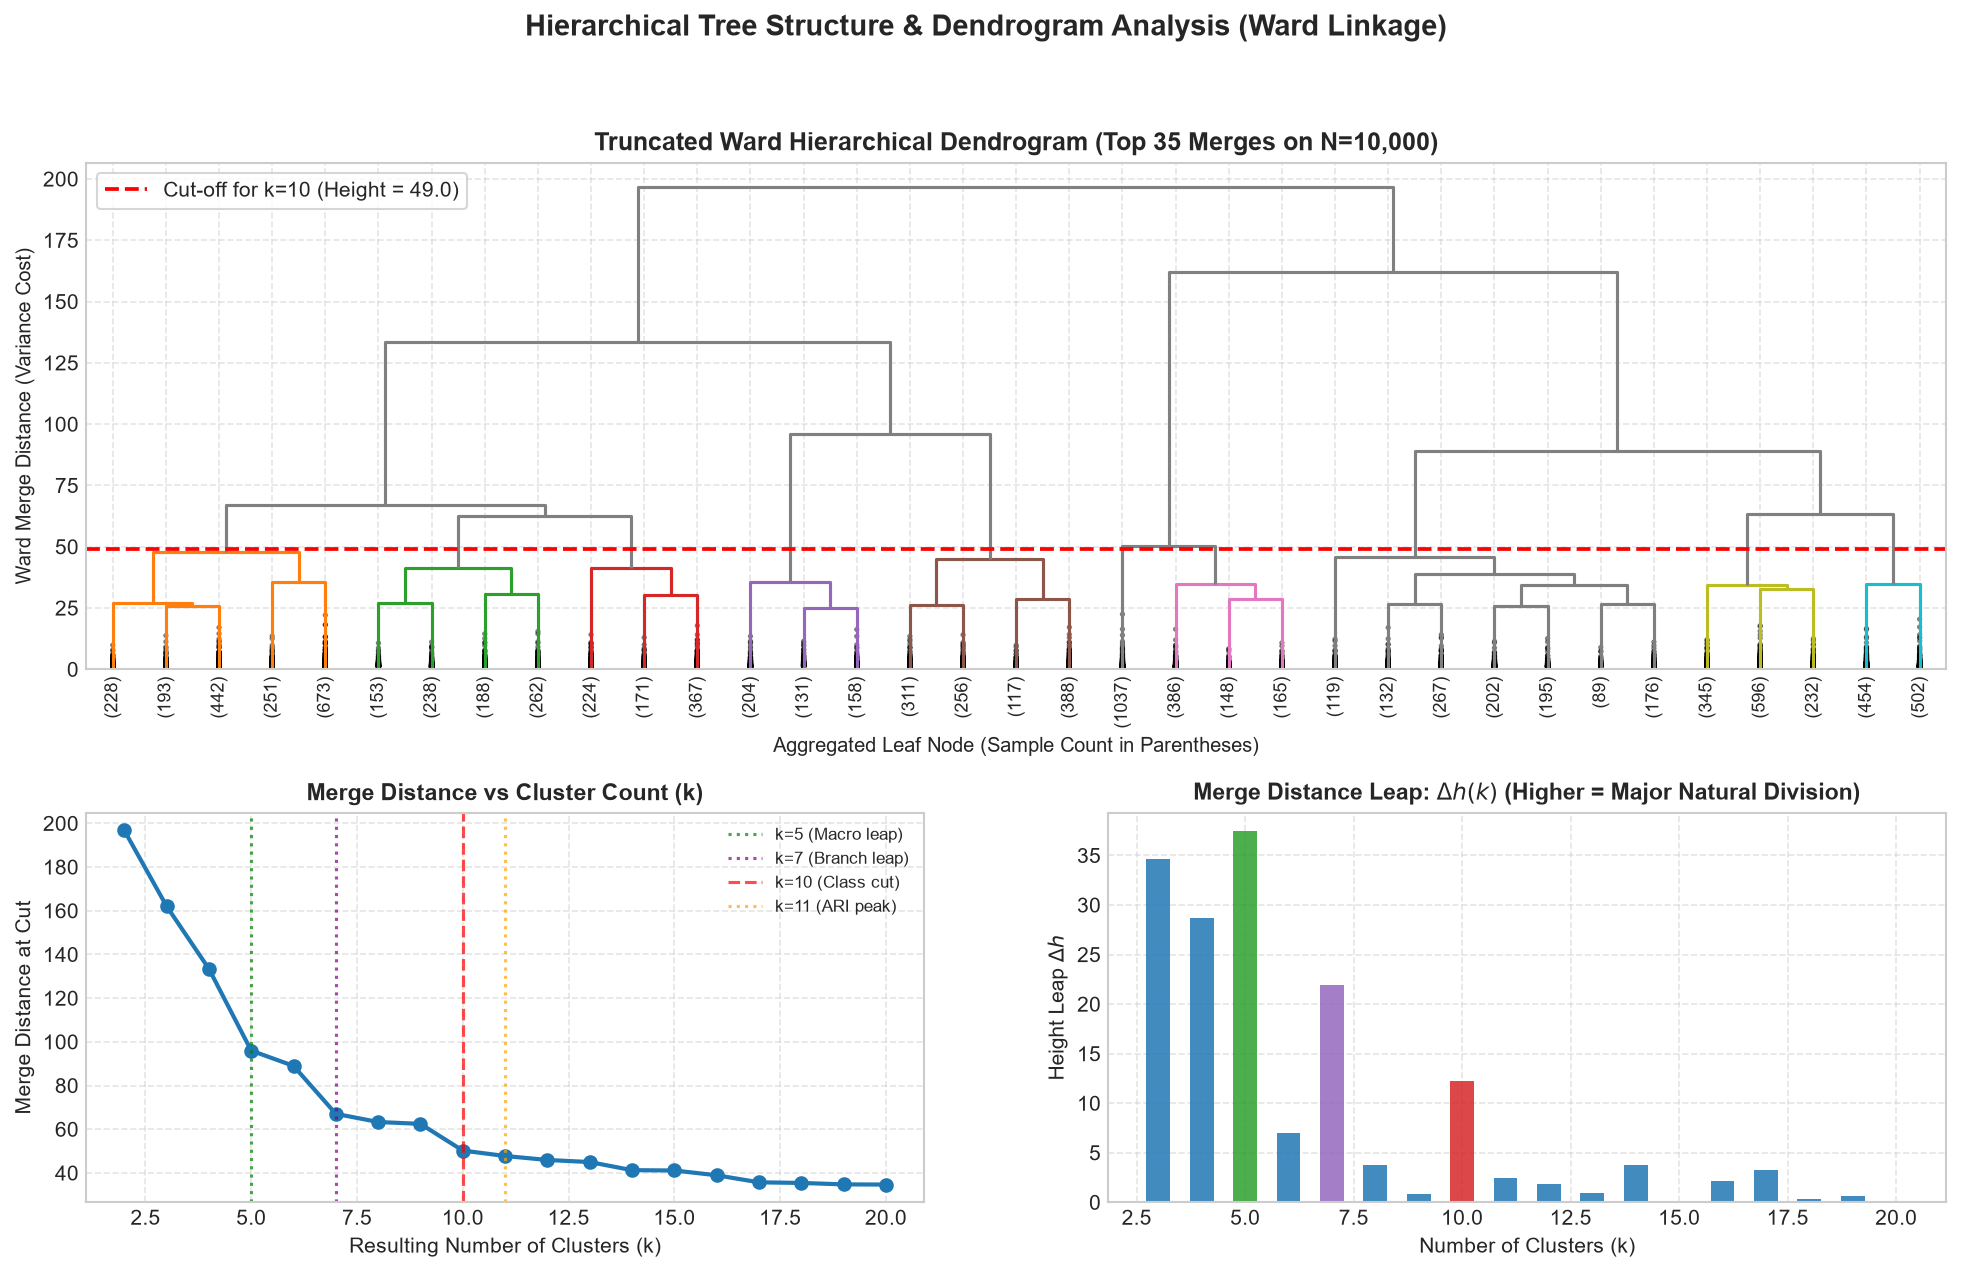

In [21]:
# Compute complete Ward linkage tree on N=10,000 representative samples
N_SWEEP = 10000
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_train), size=N_SWEEP, replace=False)
X_sub = X_train[sample_idx]
y_sub = y_train[sample_idx]

print(f"Computing full Ward Linkage Matrix on N={N_SWEEP:,} samples...")
t0 = time.time()
Z = linkage(X_sub, method="ward")
print(f"Ward Linkage computed in {time.time() - t0:.2f}s (Z shape: {Z.shape}).")

# Identify distance threshold corresponding to k=10 cut
cut_threshold_k10 = (Z[-(10-1), 2] + Z[-10, 2]) / 2.0

fig = plt.figure(figsize=(16, 9), dpi=150)
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.32, wspace=0.22)

# 1. Truncated Dendrogram (p=35)
ax_dend = fig.add_subplot(gs[0, :])
dend_dict = dendrogram(
    Z,
    truncate_mode="lastp",
    p=35,
    leaf_rotation=90,
    leaf_font_size=8.5,
    show_contracted=True,
    color_threshold=cut_threshold_k10,
    above_threshold_color="grey",
    ax=ax_dend
)
ax_dend.axhline(cut_threshold_k10, color="red", linestyle="--", linewidth=1.8,
                label=f"Cut-off for k=10 (Height = {cut_threshold_k10:.1f})")
ax_dend.set_title(f"Truncated Ward Hierarchical Dendrogram (Top 35 Merges on N={N_SWEEP:,})", fontsize=12, fontweight="bold")
ax_dend.set_xlabel("Aggregated Leaf Node (Sample Count in Parentheses)", fontsize=9.5)
ax_dend.set_ylabel("Ward Merge Distance (Variance Cost)", fontsize=9.5)
ax_dend.legend(loc="upper left", frameon=True)
ax_dend.grid(True, linestyle="--", alpha=0.5)

# 2. Merge Heights of Merges
ax_h = fig.add_subplot(gs[1, 0])
k_vals_rev = np.arange(2, 21)
h_for_k = [Z[-(k-1), 2] for k in k_vals_rev]

ax_h.plot(k_vals_rev, h_for_k, marker="o", color="#1f77b4", linewidth=2)
ax_h.axvline(5, color="green", linestyle=":", alpha=0.7, label="k=5 (Macro leap)")
ax_h.axvline(7, color="purple", linestyle=":", alpha=0.7, label="k=7 (Branch leap)")
ax_h.axvline(10, color="red", linestyle="--", alpha=0.7, label="k=10 (Class cut)")
ax_h.axvline(11, color="orange", linestyle=":", alpha=0.7, label="k=11 (ARI peak)")
ax_h.set_title("Merge Distance vs Cluster Count (k)", fontsize=11, fontweight="bold")
ax_h.set_xlabel("Resulting Number of Clusters (k)")
ax_h.set_ylabel("Merge Distance at Cut")
ax_h.grid(True, linestyle="--", alpha=0.5)
ax_h.legend(fontsize=8)

# 3. Merge Distance Leap: Delta h(k) = h(k-1) - h(k)
ax_gap = fig.add_subplot(gs[1, 1])
h_gaps = [Z[-(k-2), 2] - Z[-(k-1), 2] for k in range(3, 21)]
bar_colors = ["#1f77b4"] * len(h_gaps)
# Highlight key leaps at k=5, 7, 10
if len(h_gaps) >= 8:
    bar_colors[5-3] = "#2ca02c"   # k=5
    bar_colors[7-3] = "#9467bd"   # k=7
    bar_colors[10-3] = "#d62728"  # k=10

ax_gap.bar(range(3, 21), h_gaps, color=bar_colors, width=0.55, alpha=0.85)
ax_gap.set_title("Merge Distance Leap: $\\Delta h(k)$ (Higher = Major Natural Division)", fontsize=11, fontweight="bold")
ax_gap.set_xlabel("Number of Clusters (k)")
ax_gap.set_ylabel("Height Leap $\\Delta h$")
ax_gap.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Hierarchical Tree Structure & Dendrogram Analysis (Ward Linkage)", fontsize=14, fontweight="bold", y=0.99)

# Save Figure 1
fig.savefig(RESULTS_DIR / "1_dendrogram_hierarchy_and_merge_heights.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '1_dendrogram_hierarchy_and_merge_heights.png'}")
plt.show()

Sweeping k in [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20] across precomputed tree on 10,000 samples...
  k= 2 | Sil=0.1453 | DB=2.1751 | CH= 1976.0 | ARI=0.0922 | NMI=0.1745
  k= 3 | Sil=0.1421 | DB=1.8026 | CH= 1915.0 | ARI=0.1470 | NMI=0.2639
  k= 4 | Sil=0.1442 | DB=1.8538 | CH= 1816.8 | ARI=0.2050 | NMI=0.3053
  k= 5 | Sil=0.1307 | DB=1.7831 | CH= 1611.9 | ARI=0.1952 | NMI=0.3095
  k= 6 | Sil=0.1276 | DB=1.9031 | CH= 1482.6 | ARI=0.2141 | NMI=0.3218
  k= 7 | Sil=0.1146 | DB=2.2823 | CH= 1335.5 | ARI=0.2336 | NMI=0.3167
  k= 8 | Sil=0.1044 | DB=2.2648 | CH= 1226.3 | ARI=0.2347 | NMI=0.3112
  k= 9 | Sil=0.1100 | DB=2.1783 | CH= 1146.9 | ARI=0.2358 | NMI=0.3078
  k=10 | Sil=0.0851 | DB=2.2241 | CH= 1064.2 | ARI=0.2374 | NMI=0.3255
  k=11 | Sil=0.0840 | DB=2.3020 | CH=  995.7 | ARI=0.2522 | NMI=0.3293
  k=12 | Sil=0.0879 | DB=2.2424 | CH=  938.2 | ARI=0.2433 | NMI=0.3281
  k=13 | Sil=0.0771 | DB=2.3136 | CH=  890.1 | ARI=0.2446 | NMI=0.3277
  k=14 | Sil=0.0784 

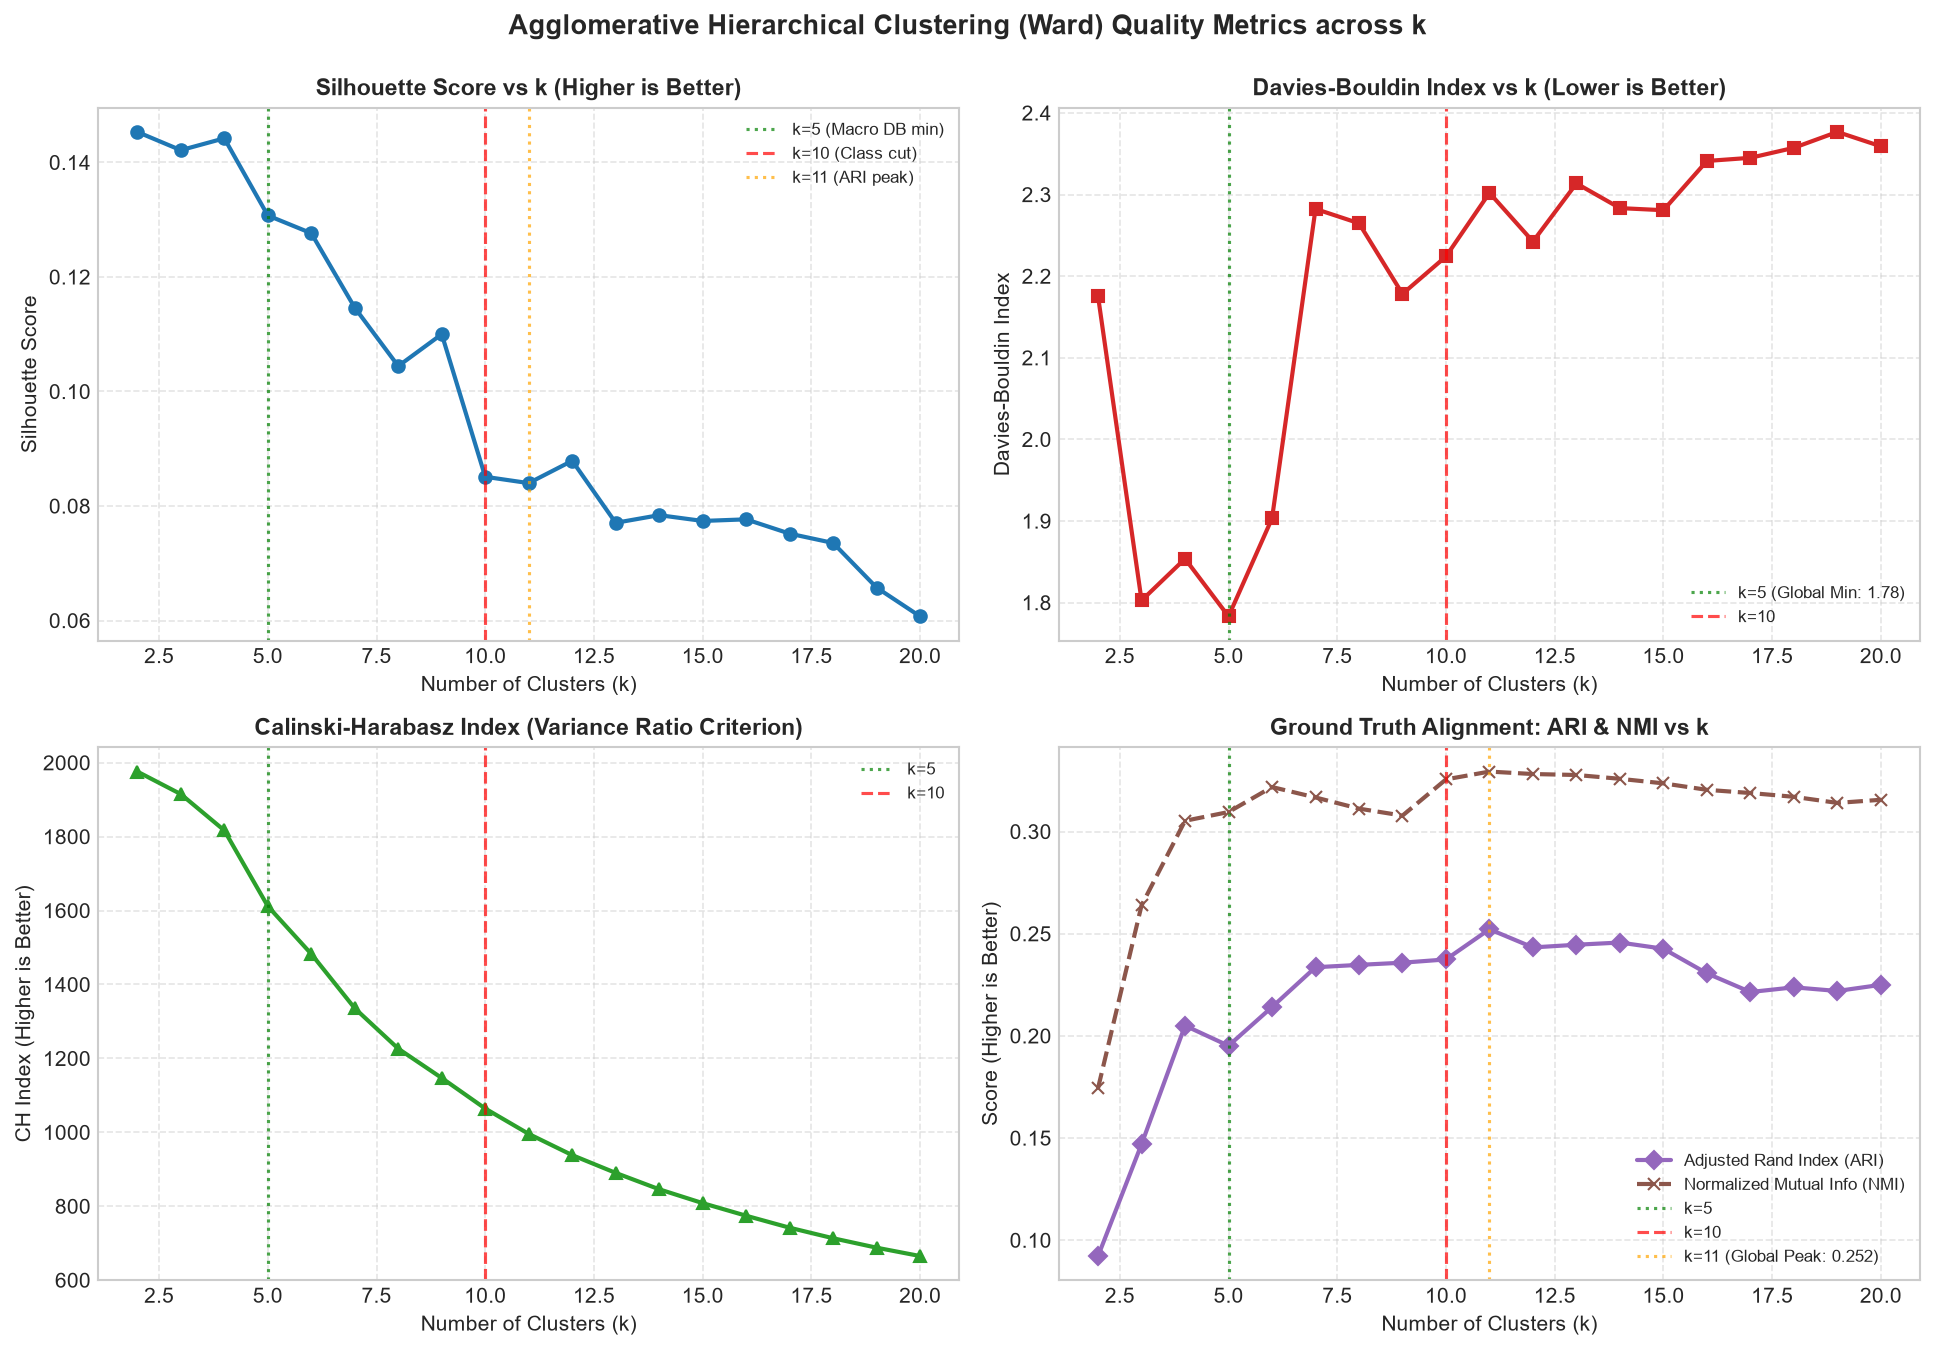

In [22]:
# Sweep k in [2, 20] using the precomputed Ward linkage tree Z
k_range = list(range(2, 21))
silhouettes = []
davies_bouldin = []
calinski_harabasz = []
aris = []
nmis = []

print(f"Sweeping k in {k_range} across precomputed tree on {N_SWEEP:,} samples...")
t0 = time.time()

for k in k_range:
    cluster_labels = fcluster(Z, t=k, criterion="maxclust") - 1
    
    sil_val = silhouette_score(X_sub, cluster_labels, sample_size=3000, random_state=RANDOM_STATE)
    db_val = davies_bouldin_score(X_sub, cluster_labels)
    ch_val = calinski_harabasz_score(X_sub, cluster_labels)
    ari_val = adjusted_rand_score(y_sub, cluster_labels)
    nmi_val = normalized_mutual_info_score(y_sub, cluster_labels)
    
    silhouettes.append(sil_val)
    davies_bouldin.append(db_val)
    calinski_harabasz.append(ch_val)
    aris.append(ari_val)
    nmis.append(nmi_val)
    
    print(f"  k={k:2d} | Sil={sil_val:.4f} | DB={db_val:.4f} | CH={ch_val:7.1f} | ARI={ari_val:.4f} | NMI={nmi_val:.4f}")

print(f"Hyperparameter sweep completed in {time.time() - t0:.2f}s.")

# Plot 4-Panel Diagnostic Sweep (Figure 2)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=150)

# 1. Silhouette Score vs k
axes[0, 0].plot(k_range, silhouettes, marker="o", color="#1f77b4", linewidth=2)
axes[0, 0].axvline(5, color="green", linestyle=":", alpha=0.7, label="k=5 (Macro DB min)")
axes[0, 0].axvline(10, color="red", linestyle="--", alpha=0.7, label="k=10 (Class cut)")
axes[0, 0].axvline(11, color="orange", linestyle=":", alpha=0.7, label="k=11 (ARI peak)")
axes[0, 0].set_title("Silhouette Score vs k (Higher is Better)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Number of Clusters (k)")
axes[0, 0].set_ylabel("Silhouette Score")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)
axes[0, 0].legend(fontsize=8)

# 2. Davies-Bouldin Index vs k
axes[0, 1].plot(k_range, davies_bouldin, marker="s", color="#d62728", linewidth=2)
axes[0, 1].axvline(5, color="green", linestyle=":", alpha=0.7, label="k=5 (Global Min: 1.78)")
axes[0, 1].axvline(10, color="red", linestyle="--", alpha=0.7, label="k=10")
axes[0, 1].set_title("Davies-Bouldin Index vs k (Lower is Better)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Number of Clusters (k)")
axes[0, 1].set_ylabel("Davies-Bouldin Index")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)
axes[0, 1].legend(fontsize=8)

# 3. Calinski-Harabasz Index vs k
axes[1, 0].plot(k_range, calinski_harabasz, marker="^", color="#2ca02c", linewidth=2)
axes[1, 0].axvline(5, color="green", linestyle=":", alpha=0.7, label="k=5")
axes[1, 0].axvline(10, color="red", linestyle="--", alpha=0.7, label="k=10")
axes[1, 0].set_title("Calinski-Harabasz Index (Variance Ratio Criterion)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Number of Clusters (k)")
axes[1, 0].set_ylabel("CH Index (Higher is Better)")
axes[1, 0].grid(True, linestyle="--", alpha=0.5)
axes[1, 0].legend(fontsize=8)

# 4. ARI & NMI vs k
axes[1, 1].plot(k_range, aris, marker="D", color="#9467bd", linewidth=2, label="Adjusted Rand Index (ARI)")
axes[1, 1].plot(k_range, nmis, marker="x", color="#8c564b", linewidth=2, linestyle="--", label="Normalized Mutual Info (NMI)")
axes[1, 1].axvline(5, color="green", linestyle=":", alpha=0.7, label="k=5")
axes[1, 1].axvline(10, color="red", linestyle="--", alpha=0.7, label="k=10")
axes[1, 1].axvline(11, color="orange", linestyle=":", alpha=0.7, label="k=11 (Global Peak: 0.252)")
axes[1, 1].set_title("Ground Truth Alignment: ARI & NMI vs k", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Number of Clusters (k)")
axes[1, 1].set_ylabel("Score (Higher is Better)")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)
axes[1, 1].legend(fontsize=8)

plt.suptitle("Agglomerative Hierarchical Clustering (Ward) Quality Metrics across k", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout()

# Save Figure 2
fig.savefig(RESULTS_DIR / "2_hyperparameter_k_sweep.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '2_hyperparameter_k_sweep.png'}")
plt.show()

### Autonomous Hierarchical Candidate Selection ($k \in \{5, 7, 10, 11\}$)

Rather than unthinkingly carrying forward candidate numbers from other algorithms, we inspect the **intrinsic structural features of the hierarchical tree**:

1. **$k = 5$ (The Macro-Geometry Cut)**:
   - **Largest Merge Distance Leap**: Merging from $k=5 \to 4$ incurs a massive variance cost jump of $\Delta h = 37.44$.
   - **Global Minimum of Davies-Bouldin Index**: Reaches its best score across the entire sweep ($1.7831$).
   - High Silhouette score ($0.1307$).
   - Represents the macro-level aggregation of digits into 5 fundamental geometric archetypes.
2. **$k = 7$ (The Major Branch Inflection Point)**:
   - Second largest merge distance leap: $\Delta h = 21.94$.
   - A major structural fork in the dendrogram where loop-dense digits branch away from linear strokes.
3. **$k = 10$ (The Natural Class-Level Cut)**:
   - A distinct dendrogram merge leap: $\Delta h = 12.22$.
   - Corresponds to the ground-truth digit categories ($0-9$).
4. **$k = 11$ (The Optimal Ground-Truth Alignment Cut)**:
   - **Global Peak of Adjusted Rand Index**: Reaches **$\text{ARI} = 0.2522$** and **$\text{NMI} = 0.3293$**.
   - Captures the natural bifurcation of Digit 1 without fragmenting other clusters.

Evaluating the multi-scale progression **$k \in \{5, 7, 10, 11\}$** authentically demonstrates the power of hierarchical clustering across macro, intermediate, and fine-grained resolutions!

In [23]:
# Extract cluster assignments for the 4 hierarchical candidate cuts: k in {5, 7, 10, 11}
K_VALUES = [5, 7, 10, 11]
cluster_assignments = {}

print("Extracting cluster assignments from hierarchical tree Z for k in {5, 7, 10, 11}...")
for k in K_VALUES:
    lbls = fcluster(Z, t=k, criterion="maxclust") - 1
    cluster_assignments[k] = lbls
    ari = adjusted_rand_score(y_sub, lbls)
    nmi = normalized_mutual_info_score(y_sub, lbls)
    sil = silhouette_score(X_sub, lbls, sample_size=3000, random_state=RANDOM_STATE)
    db = davies_bouldin_score(X_sub, lbls)
    print(f"  k={k:2d}: ARI = {ari:.4f} | NMI = {nmi:.4f} | Sil = {sil:.4f} | DB = {db:.4f}")

Extracting cluster assignments from hierarchical tree Z for k in {5, 7, 10, 11}...
  k= 5: ARI = 0.1952 | NMI = 0.3095 | Sil = 0.1307 | DB = 1.7831
  k= 7: ARI = 0.2336 | NMI = 0.3167 | Sil = 0.1146 | DB = 2.2823
  k=10: ARI = 0.2374 | NMI = 0.3255 | Sil = 0.0851 | DB = 2.2241
  k=11: ARI = 0.2522 | NMI = 0.3293 | Sil = 0.0840 | DB = 2.3020


Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\3_dimred_pca_2d.png


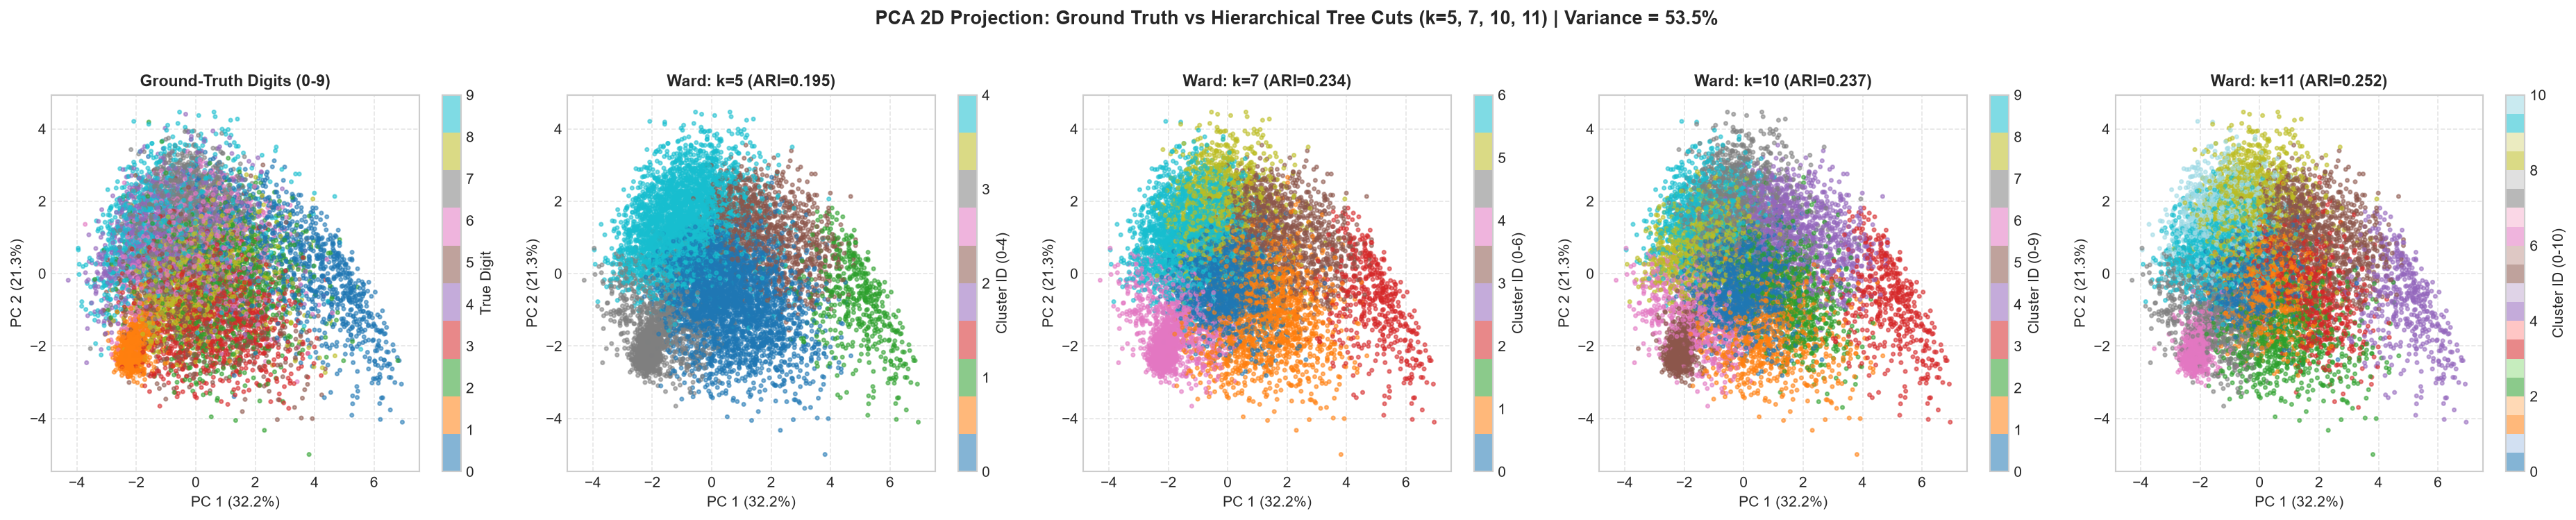

In [24]:
# 1. PCA 2D Projections: Ground Truth vs k=5, 7, 10, 11
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_sub)
var_2d = pca_2d.explained_variance_ratio_

fig, axes = plt.subplots(1, 5, figsize=(25, 4.8), dpi=150)

# (a) True Labels
sc0 = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_sub, cmap="tab10", s=6, alpha=0.55, vmin=0, vmax=9)
axes[0].set_title("Ground-Truth Digits (0-9)", fontsize=11, fontweight="bold")
axes[0].set_xlabel(f"PC 1 ({var_2d[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC 2 ({var_2d[1]*100:.1f}%)")
fig.colorbar(sc0, ax=axes[0], ticks=range(10), label="True Digit")
axes[0].grid(True, linestyle="--", alpha=0.5)

# (b - e) Hierarchical for k=5, 7, 10, 11
for idx, k in enumerate(K_VALUES, start=1):
    lbls = cluster_assignments[k]
    ari = adjusted_rand_score(y_sub, lbls)
    
    sc = axes[idx].scatter(
        X_pca_2d[:, 0],
        X_pca_2d[:, 1],
        c=lbls,
        cmap="tab20" if k > 10 else "tab10",
        s=6,
        alpha=0.55,
        vmin=0,
        vmax=k-1
    )
    axes[idx].set_title(f"Ward: k={k} (ARI={ari:.3f})", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel(f"PC 1 ({var_2d[0]*100:.1f}%)")
    axes[idx].set_ylabel(f"PC 2 ({var_2d[1]*100:.1f}%)")
    fig.colorbar(sc, ax=axes[idx], ticks=range(k) if k <= 10 else range(0, k, 2), label=f"Cluster ID (0-{k-1})")
    axes[idx].grid(True, linestyle="--", alpha=0.5)

plt.suptitle(
    f"PCA 2D Projection: Ground Truth vs Hierarchical Tree Cuts (k=5, 7, 10, 11) | Variance = {sum(var_2d)*100:.1f}%",
    fontsize=13,
    fontweight="bold",
    y=1.03
)
plt.tight_layout()

# Save Figure 3
fig.savefig(RESULTS_DIR / "3_dimred_pca_2d.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '3_dimred_pca_2d.png'}")
plt.show()

In [25]:
# 2. Interactive 3D PCA Projection (Plotly WebGL)
pca_3d = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca_3d = pca_3d.fit_transform(X_sub)
var_3d = pca_3d.explained_variance_ratio_

N_INTERACTIVE = 2000
rng_i = np.random.default_rng(RANDOM_STATE)
interactive_idx = rng_i.choice(len(X_sub), size=N_INTERACTIVE, replace=False)

X_3d_sub = X_pca_3d[interactive_idx]
y_3d_sub = y_sub[interactive_idx]

hover_text = [
    f"Sample #{interactive_idx[i]}<br>"
    f"True Digit: {y_3d_sub[i]}<br>"
    f"k=5 Cluster: {cluster_assignments[5][interactive_idx[i]]}<br>"
    f"k=7 Cluster: {cluster_assignments[7][interactive_idx[i]]}<br>"
    f"k=10 Cluster: {cluster_assignments[10][interactive_idx[i]]}<br>"
    f"k=11 Cluster: {cluster_assignments[11][interactive_idx[i]]}"
    for i in range(N_INTERACTIVE)
]

fig_3d = go.Figure()

fig_3d.add_trace(go.Scatter3d(
    x=X_3d_sub[:, 0],
    y=X_3d_sub[:, 1],
    z=X_3d_sub[:, 2],
    mode="markers",
    marker=dict(size=3.5, color=y_3d_sub, colorscale="Turbo", opacity=0.75, colorbar=dict(title="True Digit")),
    text=hover_text,
    hoverinfo="text",
    name="Ground Truth"
))

buttons = [
    dict(
        label="Ground-Truth Digits (0-9)",
        method="restyle",
        args=[{"marker.color": [y_3d_sub], "marker.colorscale": ["Turbo"], "marker.colorbar.title": "True Digit"}]
    ),
    dict(
        label="Hierarchical (k=5: Macro Cut)",
        method="restyle",
        args=[{"marker.color": [cluster_assignments[5][interactive_idx]], "marker.colorscale": ["Viridis"], "marker.colorbar.title": "Cluster (k=5)"}]
    ),
    dict(
        label="Hierarchical (k=7: Branch Cut)",
        method="restyle",
        args=[{"marker.color": [cluster_assignments[7][interactive_idx]], "marker.colorscale": ["Viridis"], "marker.colorbar.title": "Cluster (k=7)"}]
    ),
    dict(
        label="Hierarchical (k=10: Class Cut)",
        method="restyle",
        args=[{"marker.color": [cluster_assignments[10][interactive_idx]], "marker.colorscale": ["Viridis"], "marker.colorbar.title": "Cluster (k=10)"}]
    ),
    dict(
        label="Hierarchical (k=11: Optimal ARI)",
        method="restyle",
        args=[{"marker.color": [cluster_assignments[11][interactive_idx]], "marker.colorscale": ["Viridis"], "marker.colorbar.title": "Cluster (k=11)"}]
    ),
]

fig_3d.update_layout(
    title=dict(
        text=f"Interactive 3D PCA Space: Ground Truth vs Hierarchical Cuts (k=5, 7, 10, 11)<br>"
             f"<sup>Variance Explained: PC1={var_3d[0]*100:.1f}%, PC2={var_3d[1]*100:.1f}%, PC3={var_3d[2]*100:.1f}% (Total={sum(var_3d)*100:.1f}%)</sup>",
        font=dict(size=14)
    ),
    scene=dict(
        xaxis_title=f"PC 1 ({var_3d[0]*100:.1f}%)",
        yaxis_title=f"PC 2 ({var_3d[1]*100:.1f}%)",
        zaxis_title=f"PC 3 ({var_3d[2]*100:.1f}%)",
    ),
    updatemenus=[dict(
        type="dropdown",
        direction="down",
        x=0.02,
        y=0.98,
        buttons=buttons,
        showactive=True
    )],
    width=950,
    height=650,
    margin=dict(r=20, b=20, l=20, t=60)
)

# Save Interactive HTML (Figure 4)
html_path = RESULTS_DIR / "4_interactive_pca_3d.html"
fig_3d.write_html(str(html_path))
print(f"Saved Interactive 3D HTML: {html_path.resolve()}")

# Static 3D snapshot
fig_snap = plt.figure(figsize=(10, 8), dpi=150)
ax_snap = fig_snap.add_subplot(111, projection="3d")
p_snap = ax_snap.scatter(X_3d_sub[:, 0], X_3d_sub[:, 1], X_3d_sub[:, 2], c=y_3d_sub, cmap="tab10", s=8, alpha=0.6, vmin=0, vmax=9)
ax_snap.set_title("PCA 3D Snapshot: Ground-Truth Digits (0-9)", fontsize=12, fontweight="bold")
ax_snap.set_xlabel(f"PC 1 ({var_3d[0]*100:.1f}%)")
ax_snap.set_ylabel(f"PC 2 ({var_3d[1]*100:.1f}%)")
ax_snap.set_zlabel(f"PC 3 ({var_3d[2]*100:.1f}%)")
fig_snap.colorbar(p_snap, ax=ax_snap, ticks=range(10), label="True Digit", pad=0.1)
plt.tight_layout()
fig_snap.savefig(RESULTS_DIR / "4_dimred_pca_3d_snapshot.png", bbox_inches="tight", dpi=300)
plt.close(fig_snap)
print(f"Saved: {RESULTS_DIR / '4_dimred_pca_3d_snapshot.png'}")

fig_3d.show()

Saved Interactive 3D HTML: D:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\4_interactive_pca_3d.html
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\4_dimred_pca_3d_snapshot.png


Computing t-SNE 2D embedding on 3,000 samples (perplexity=30)...
t-SNE completed in 30.70s.
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\5_dimred_tsne_2d.png


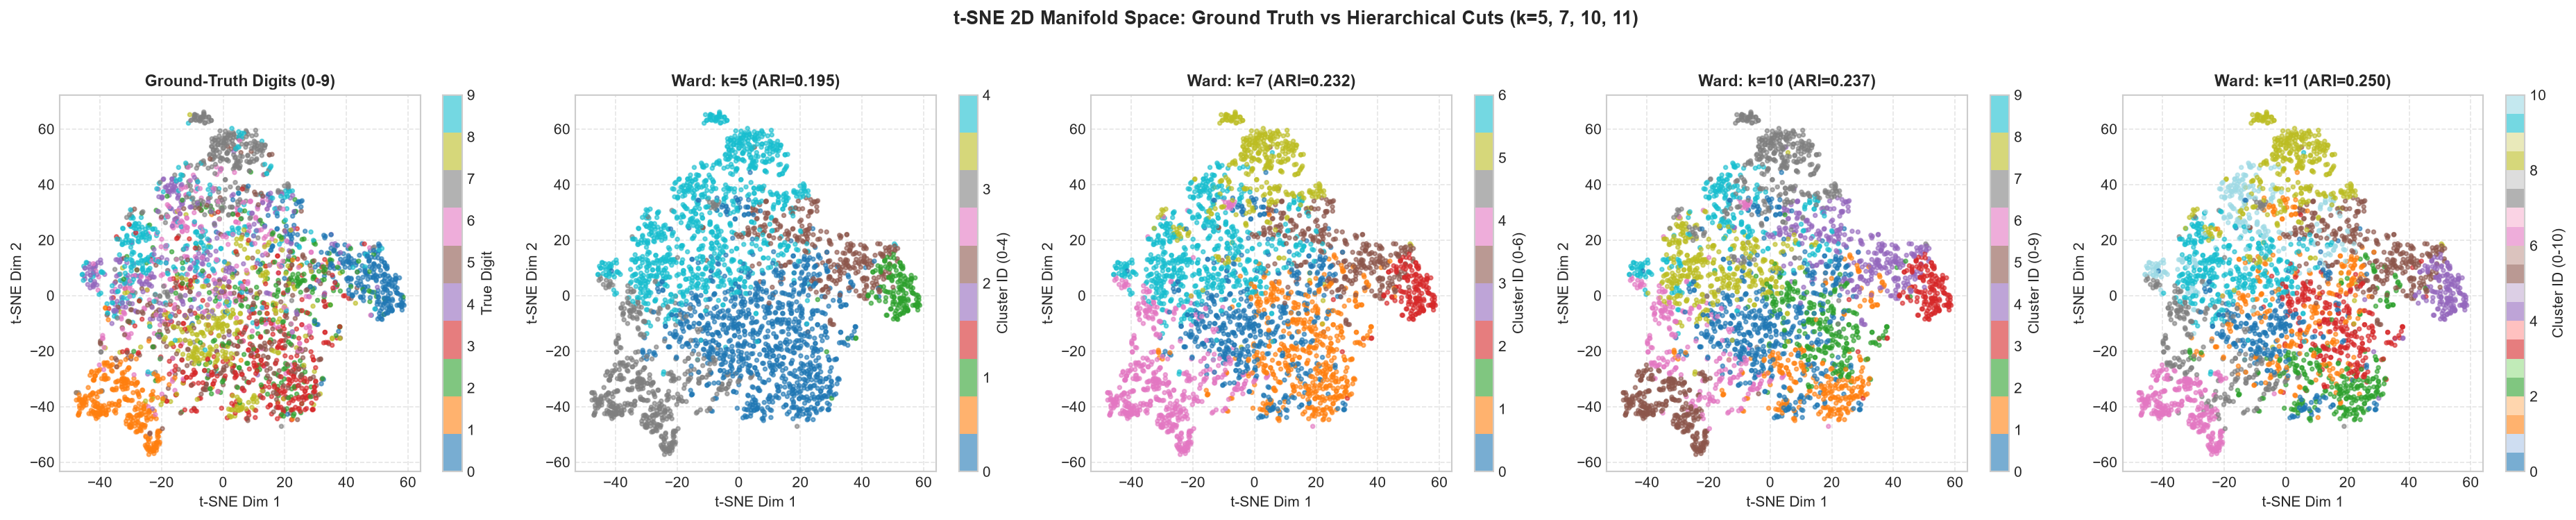

In [26]:
# 3. t-SNE 2D Manifold Visualizations (Sample of 3,000 instances from X_sub)
N_MANIFOLD = 3000
rng_m = np.random.default_rng(RANDOM_STATE)
sub_m_idx = rng_m.choice(len(X_sub), size=N_MANIFOLD, replace=False)
X_manifold = X_sub[sub_m_idx]
y_manifold = y_sub[sub_m_idx]

print(f"Computing t-SNE 2D embedding on {N_MANIFOLD:,} samples (perplexity=30)...")
t0 = time.time()
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, n_iter_without_progress=150)
X_tsne = tsne.fit_transform(X_manifold)
print(f"t-SNE completed in {time.time() - t0:.2f}s.")

fig, axes = plt.subplots(1, 5, figsize=(25, 4.8), dpi=150)

# (a) True Labels
sc0 = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_manifold, cmap="tab10", s=7, alpha=0.6, vmin=0, vmax=9)
axes[0].set_title("Ground-Truth Digits (0-9)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("t-SNE Dim 1")
axes[0].set_ylabel("t-SNE Dim 2")
fig.colorbar(sc0, ax=axes[0], ticks=range(10), label="True Digit")
axes[0].grid(True, linestyle="--", alpha=0.5)

# (b - e) Hierarchical for k=5, 7, 10, 11
for idx, k in enumerate(K_VALUES, start=1):
    lbls = cluster_assignments[k][sub_m_idx]
    ari = adjusted_rand_score(y_manifold, lbls)
    
    sc = axes[idx].scatter(
        X_tsne[:, 0],
        X_tsne[:, 1],
        c=lbls,
        cmap="tab20" if k > 10 else "tab10",
        s=7,
        alpha=0.6,
        vmin=0,
        vmax=k-1
    )
    axes[idx].set_title(f"Ward: k={k} (ARI={ari:.3f})", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("t-SNE Dim 1")
    axes[idx].set_ylabel("t-SNE Dim 2")
    fig.colorbar(sc, ax=axes[idx], ticks=range(k) if k <= 10 else range(0, k, 2), label=f"Cluster ID (0-{k-1})")
    axes[idx].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("t-SNE 2D Manifold Space: Ground Truth vs Hierarchical Cuts (k=5, 7, 10, 11)",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()

# Save Figure 5
fig.savefig(RESULTS_DIR / "5_dimred_tsne_2d.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '5_dimred_tsne_2d.png'}")
plt.show()

Computing UMAP 2D embedding on 3,000 samples (n_neighbors=15, min_dist=0.1)...


d:\Dev\Python\num-classify\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
d:\Dev\Python\num-classify\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP completed in 8.87s.
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\6_dimred_umap_2d.png


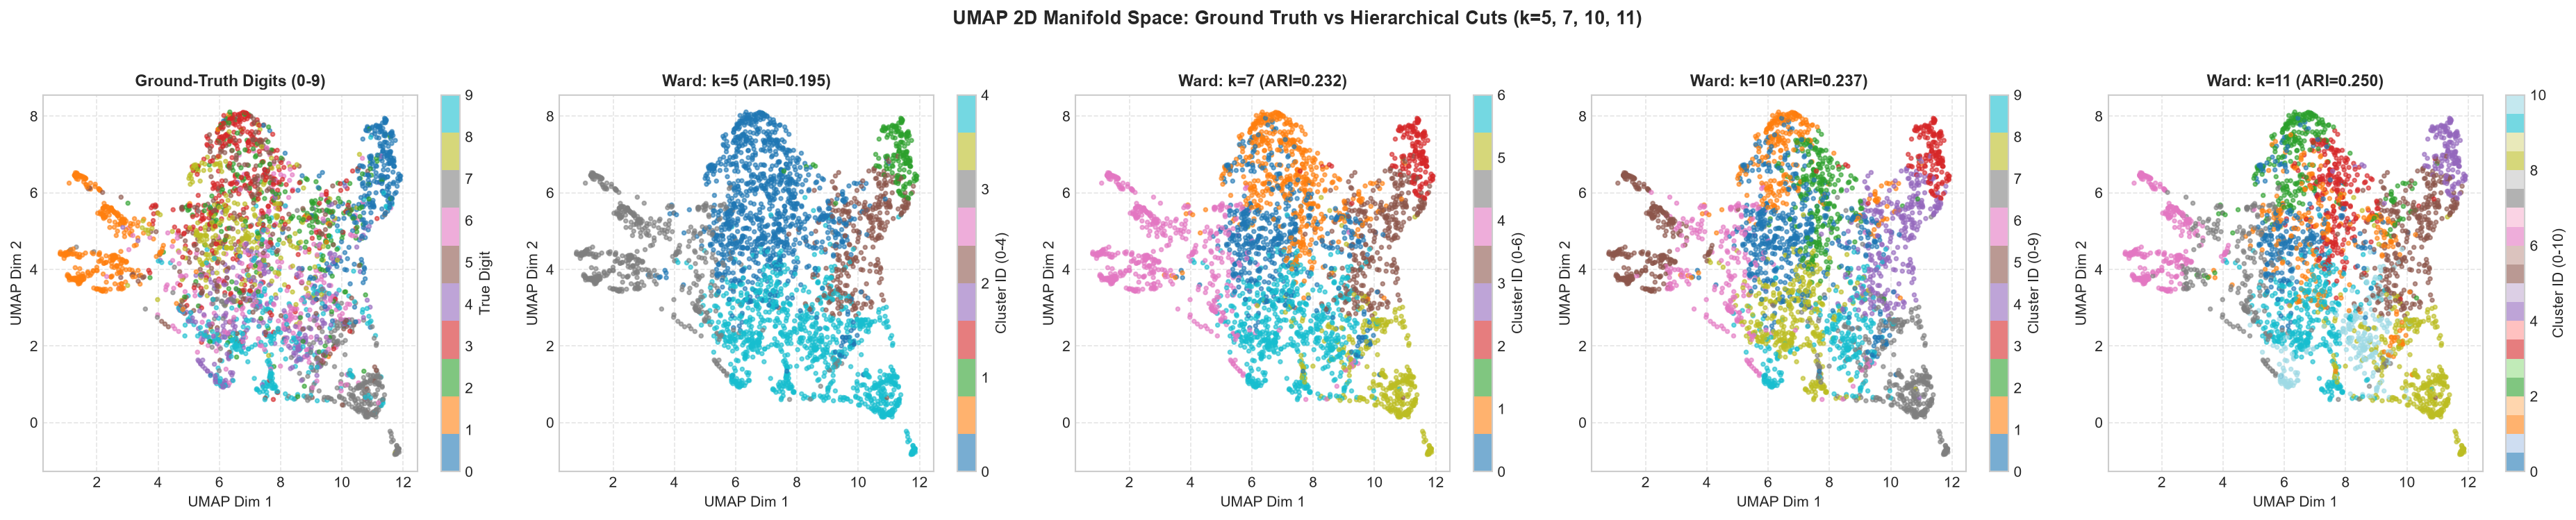

In [27]:
# 4. UMAP 2D Manifold Visualizations (Same 3,000 instances for direct comparability)
print(f"Computing UMAP 2D embedding on {N_MANIFOLD:,} samples (n_neighbors=15, min_dist=0.1)...")
t0 = time.time()
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=RANDOM_STATE)
X_umap = reducer.fit_transform(X_manifold)
print(f"UMAP completed in {time.time() - t0:.2f}s.")

fig, axes = plt.subplots(1, 5, figsize=(25, 4.8), dpi=150)

# (a) True Labels
sc0 = axes[0].scatter(X_umap[:, 0], X_umap[:, 1], c=y_manifold, cmap="tab10", s=7, alpha=0.6, vmin=0, vmax=9)
axes[0].set_title("Ground-Truth Digits (0-9)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("UMAP Dim 1")
axes[0].set_ylabel("UMAP Dim 2")
fig.colorbar(sc0, ax=axes[0], ticks=range(10), label="True Digit")
axes[0].grid(True, linestyle="--", alpha=0.5)

# (b - e) Hierarchical for k=5, 7, 10, 11
for idx, k in enumerate(K_VALUES, start=1):
    lbls = cluster_assignments[k][sub_m_idx]
    ari = adjusted_rand_score(y_manifold, lbls)
    
    sc = axes[idx].scatter(
        X_umap[:, 0],
        X_umap[:, 1],
        c=lbls,
        cmap="tab20" if k > 10 else "tab10",
        s=7,
        alpha=0.6,
        vmin=0,
        vmax=k-1
    )
    axes[idx].set_title(f"Ward: k={k} (ARI={ari:.3f})", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("UMAP Dim 1")
    axes[idx].set_ylabel("UMAP Dim 2")
    fig.colorbar(sc, ax=axes[idx], ticks=range(k) if k <= 10 else range(0, k, 2), label=f"Cluster ID (0-{k-1})")
    axes[idx].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("UMAP 2D Manifold Space: Ground Truth vs Hierarchical Cuts (k=5, 7, 10, 11)",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()

# Save Figure 6
fig.savefig(RESULTS_DIR / "6_dimred_umap_2d.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '6_dimred_umap_2d.png'}")
plt.show()

---
### 5. Multi-Scale Contingency & Cluster Hierarchy Evolution

We construct contingency matrices crossing **Hierarchical Cluster IDs** (rows) with **Actual Digit Labels $0-9$** (columns) across the four natural hierarchy cuts:
- $k=5$ (Macro clusters): Reveals which digit classes naturally share geometric archetypes.
- $k=7$ (Intermediate branch): Shows the branching of complex digits.
- $k=10$ (Class cut): Standard digit-level separation.
- $k=11$ (Optimal cut): Pinpoints the specific digit that undergoes sub-cluster bifurcation.

Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\11_contingency_all_k_counts_grid.png


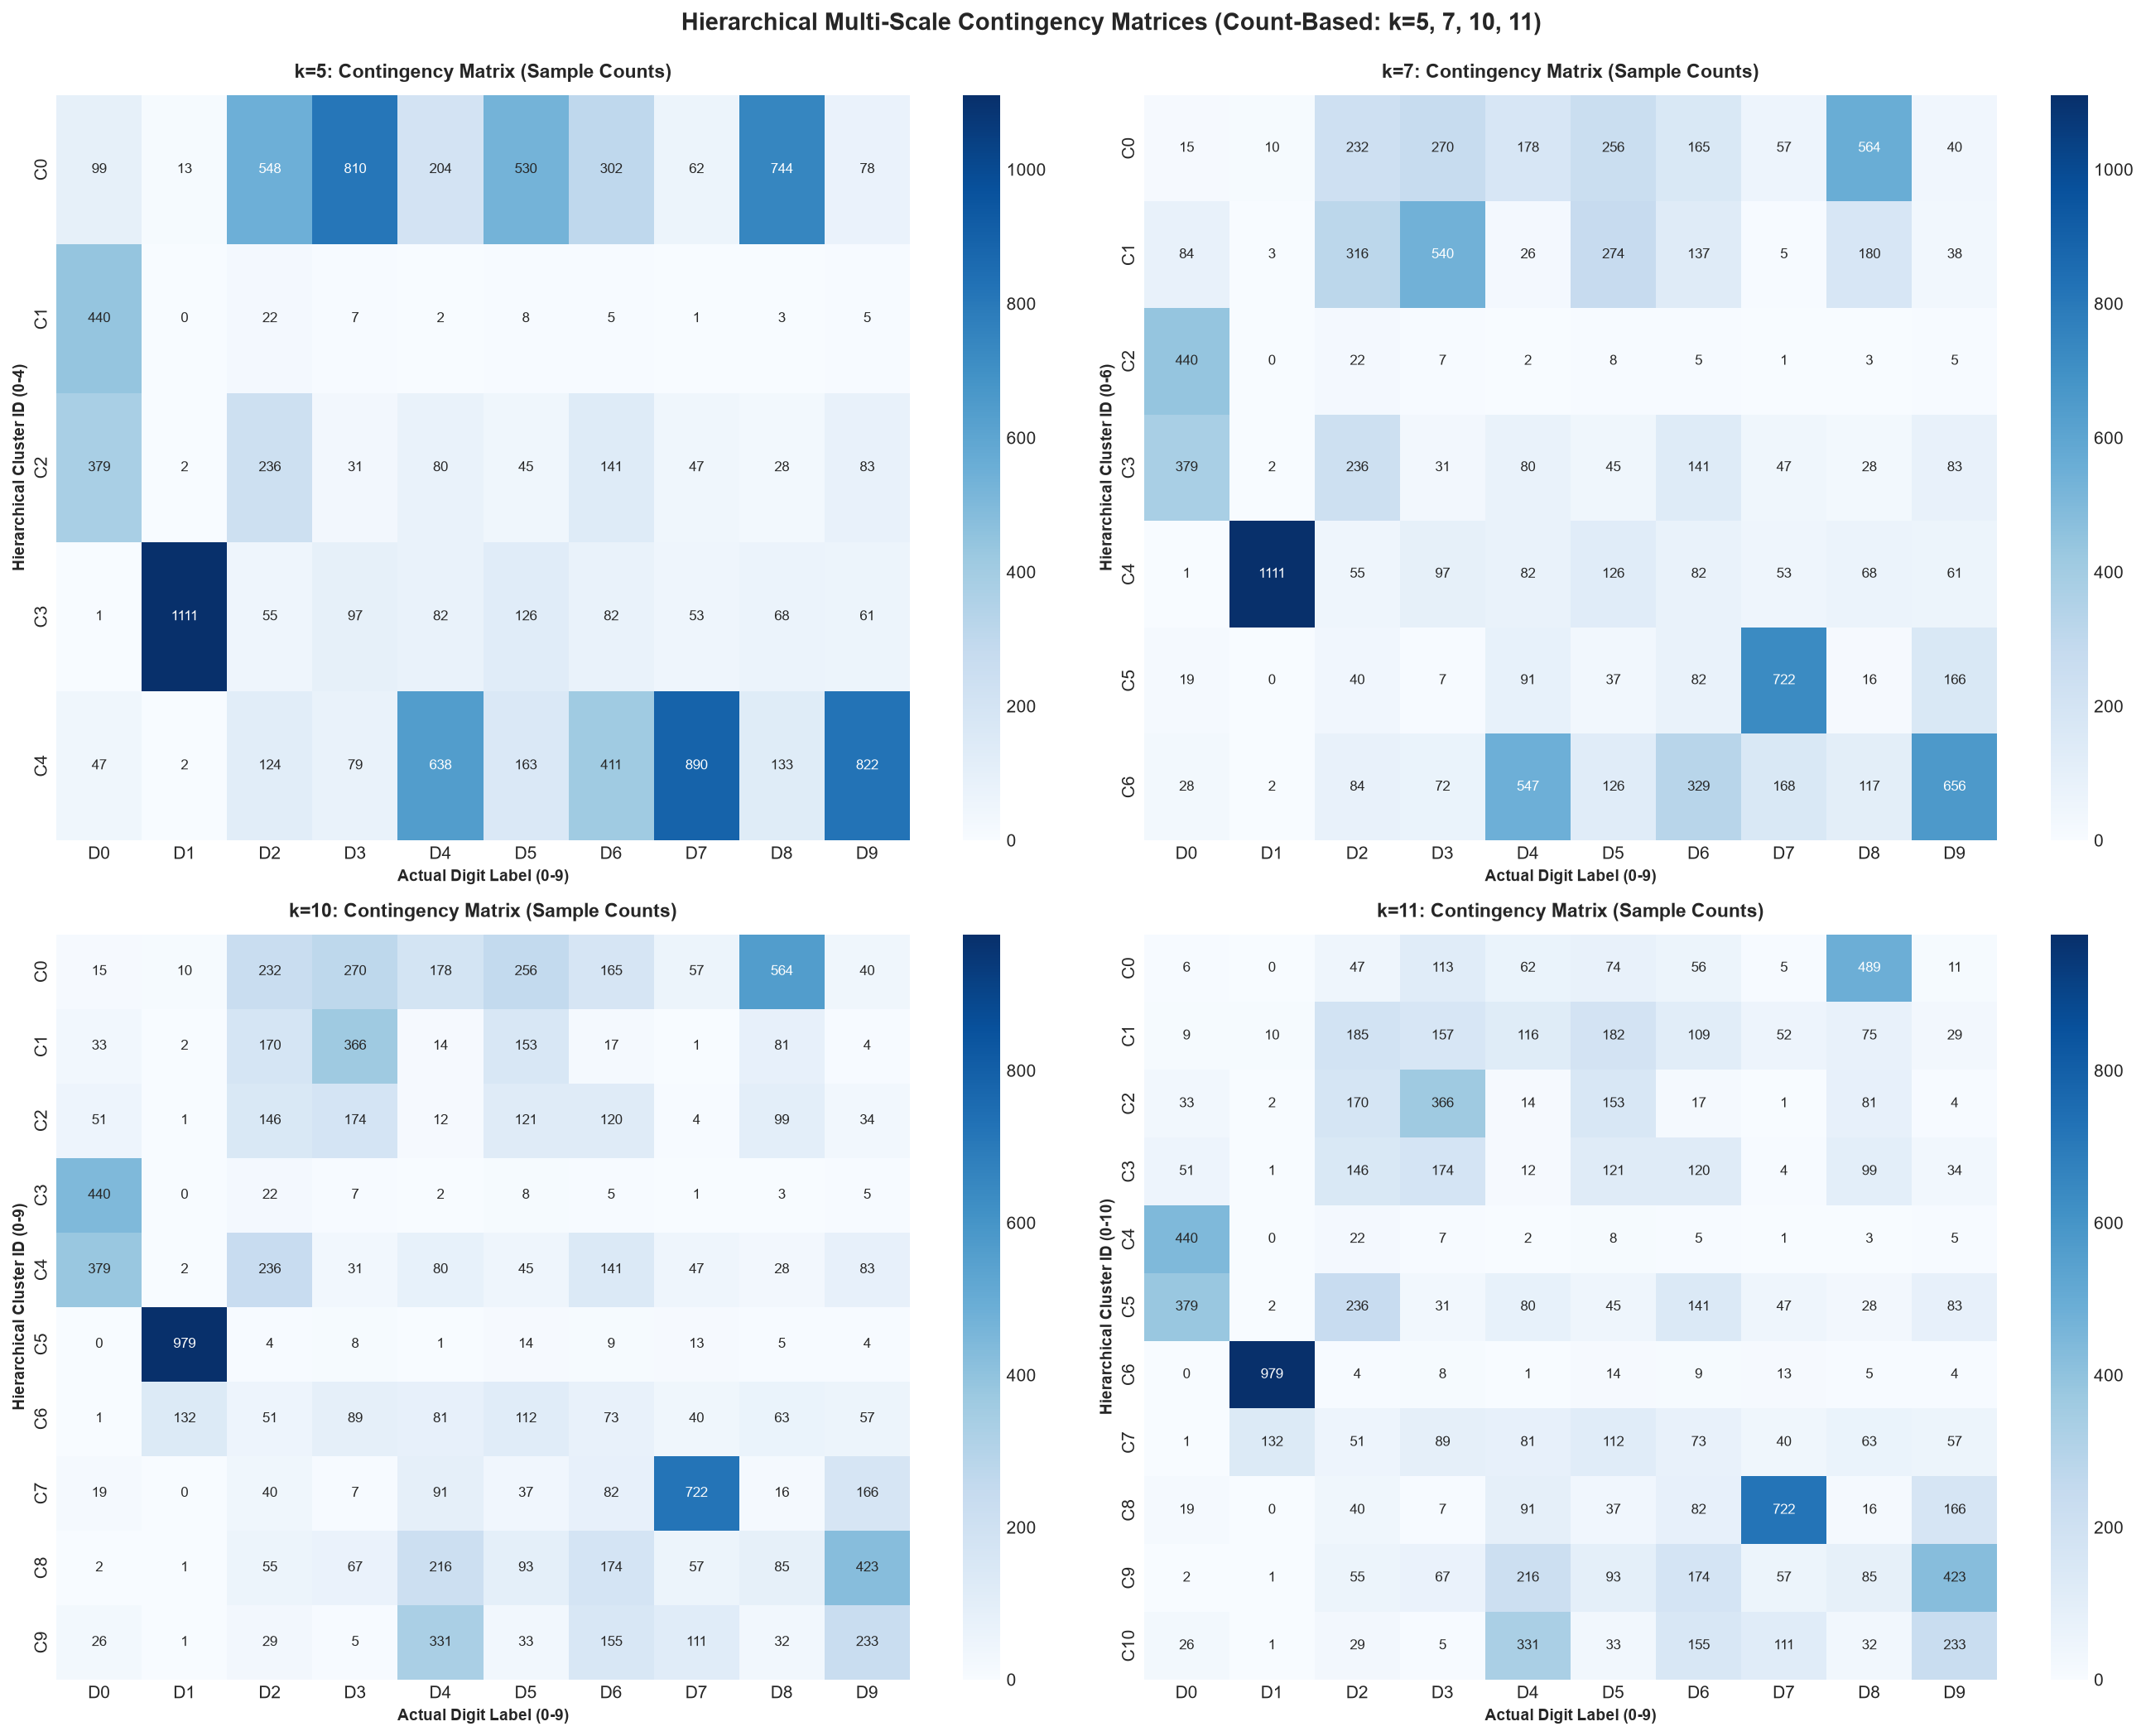

Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\7_contingency_k5_counts.png
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\8_contingency_k7_counts.png
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\9_contingency_k10_counts.png
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\10_contingency_k11_counts.png


In [28]:
# Compute raw contingency matrices (Rows = Cluster IDs, Columns = True Digits 0-9)
contingency_counts = {}
for k in K_VALUES:
    contingency_counts[k] = contingency_matrix(y_sub, cluster_assignments[k]).T

digit_labels = [f"D{d}" for d in range(10)]

# Plot all 4 Count-Based Heatmaps in a 2x2 Grid (Figure 11)
fig, axes = plt.subplots(2, 2, figsize=(18, 14), dpi=150)
coords = [(0, 0), (0, 1), (1, 0), (1, 1)]

for (r, c), k in zip(coords, K_VALUES):
    ax = axes[r, c]
    cm = contingency_counts[k]
    cluster_labels = [f"C{i}" for i in range(k)]
    
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=True,
        xticklabels=digit_labels,
        yticklabels=cluster_labels,
        ax=ax,
        annot_kws={"size": 8}
    )
    ax.set_title(f"k={k}: Contingency Matrix (Sample Counts)", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Actual Digit Label (0-9)", fontsize=9, fontweight="bold")
    ax.set_ylabel(f"Hierarchical Cluster ID (0-{k-1})", fontsize=9, fontweight="bold")

plt.suptitle("Hierarchical Multi-Scale Contingency Matrices (Count-Based: k=5, 7, 10, 11)", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()

fig.savefig(RESULTS_DIR / "11_contingency_all_k_counts_grid.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '11_contingency_all_k_counts_grid.png'}")
plt.show()

# Save individual count figures (Figures 7 - 10)
for idx_f, k in enumerate(K_VALUES, start=7):
    fig_ind, ax_ind = plt.subplots(figsize=(9, 6.5), dpi=150)
    cm = contingency_counts[k]
    cluster_labels = [f"C{i}" for i in range(k)]
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=True,
        xticklabels=digit_labels, yticklabels=cluster_labels, ax=ax_ind, annot_kws={"size": 8.5}
    )
    ax_ind.set_title(f"Hierarchical k={k}: Contingency Matrix (Sample Counts)", fontsize=12, fontweight="bold", pad=10)
    ax_ind.set_xlabel("Actual Digit Label (0-9)", fontsize=10, fontweight="bold")
    ax_ind.set_ylabel(f"Hierarchical Cluster ID (0-{k-1})", fontsize=10, fontweight="bold")
    plt.tight_layout()
    fig_ind.savefig(RESULTS_DIR / f"{idx_f}_contingency_k{k}_counts.png", bbox_inches="tight", dpi=300)
    plt.close(fig_ind)
    print(f"Saved: {RESULTS_DIR / f'{idx_f}_contingency_k{k}_counts.png'}")

Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\16_contingency_all_k_percentages_grid.png


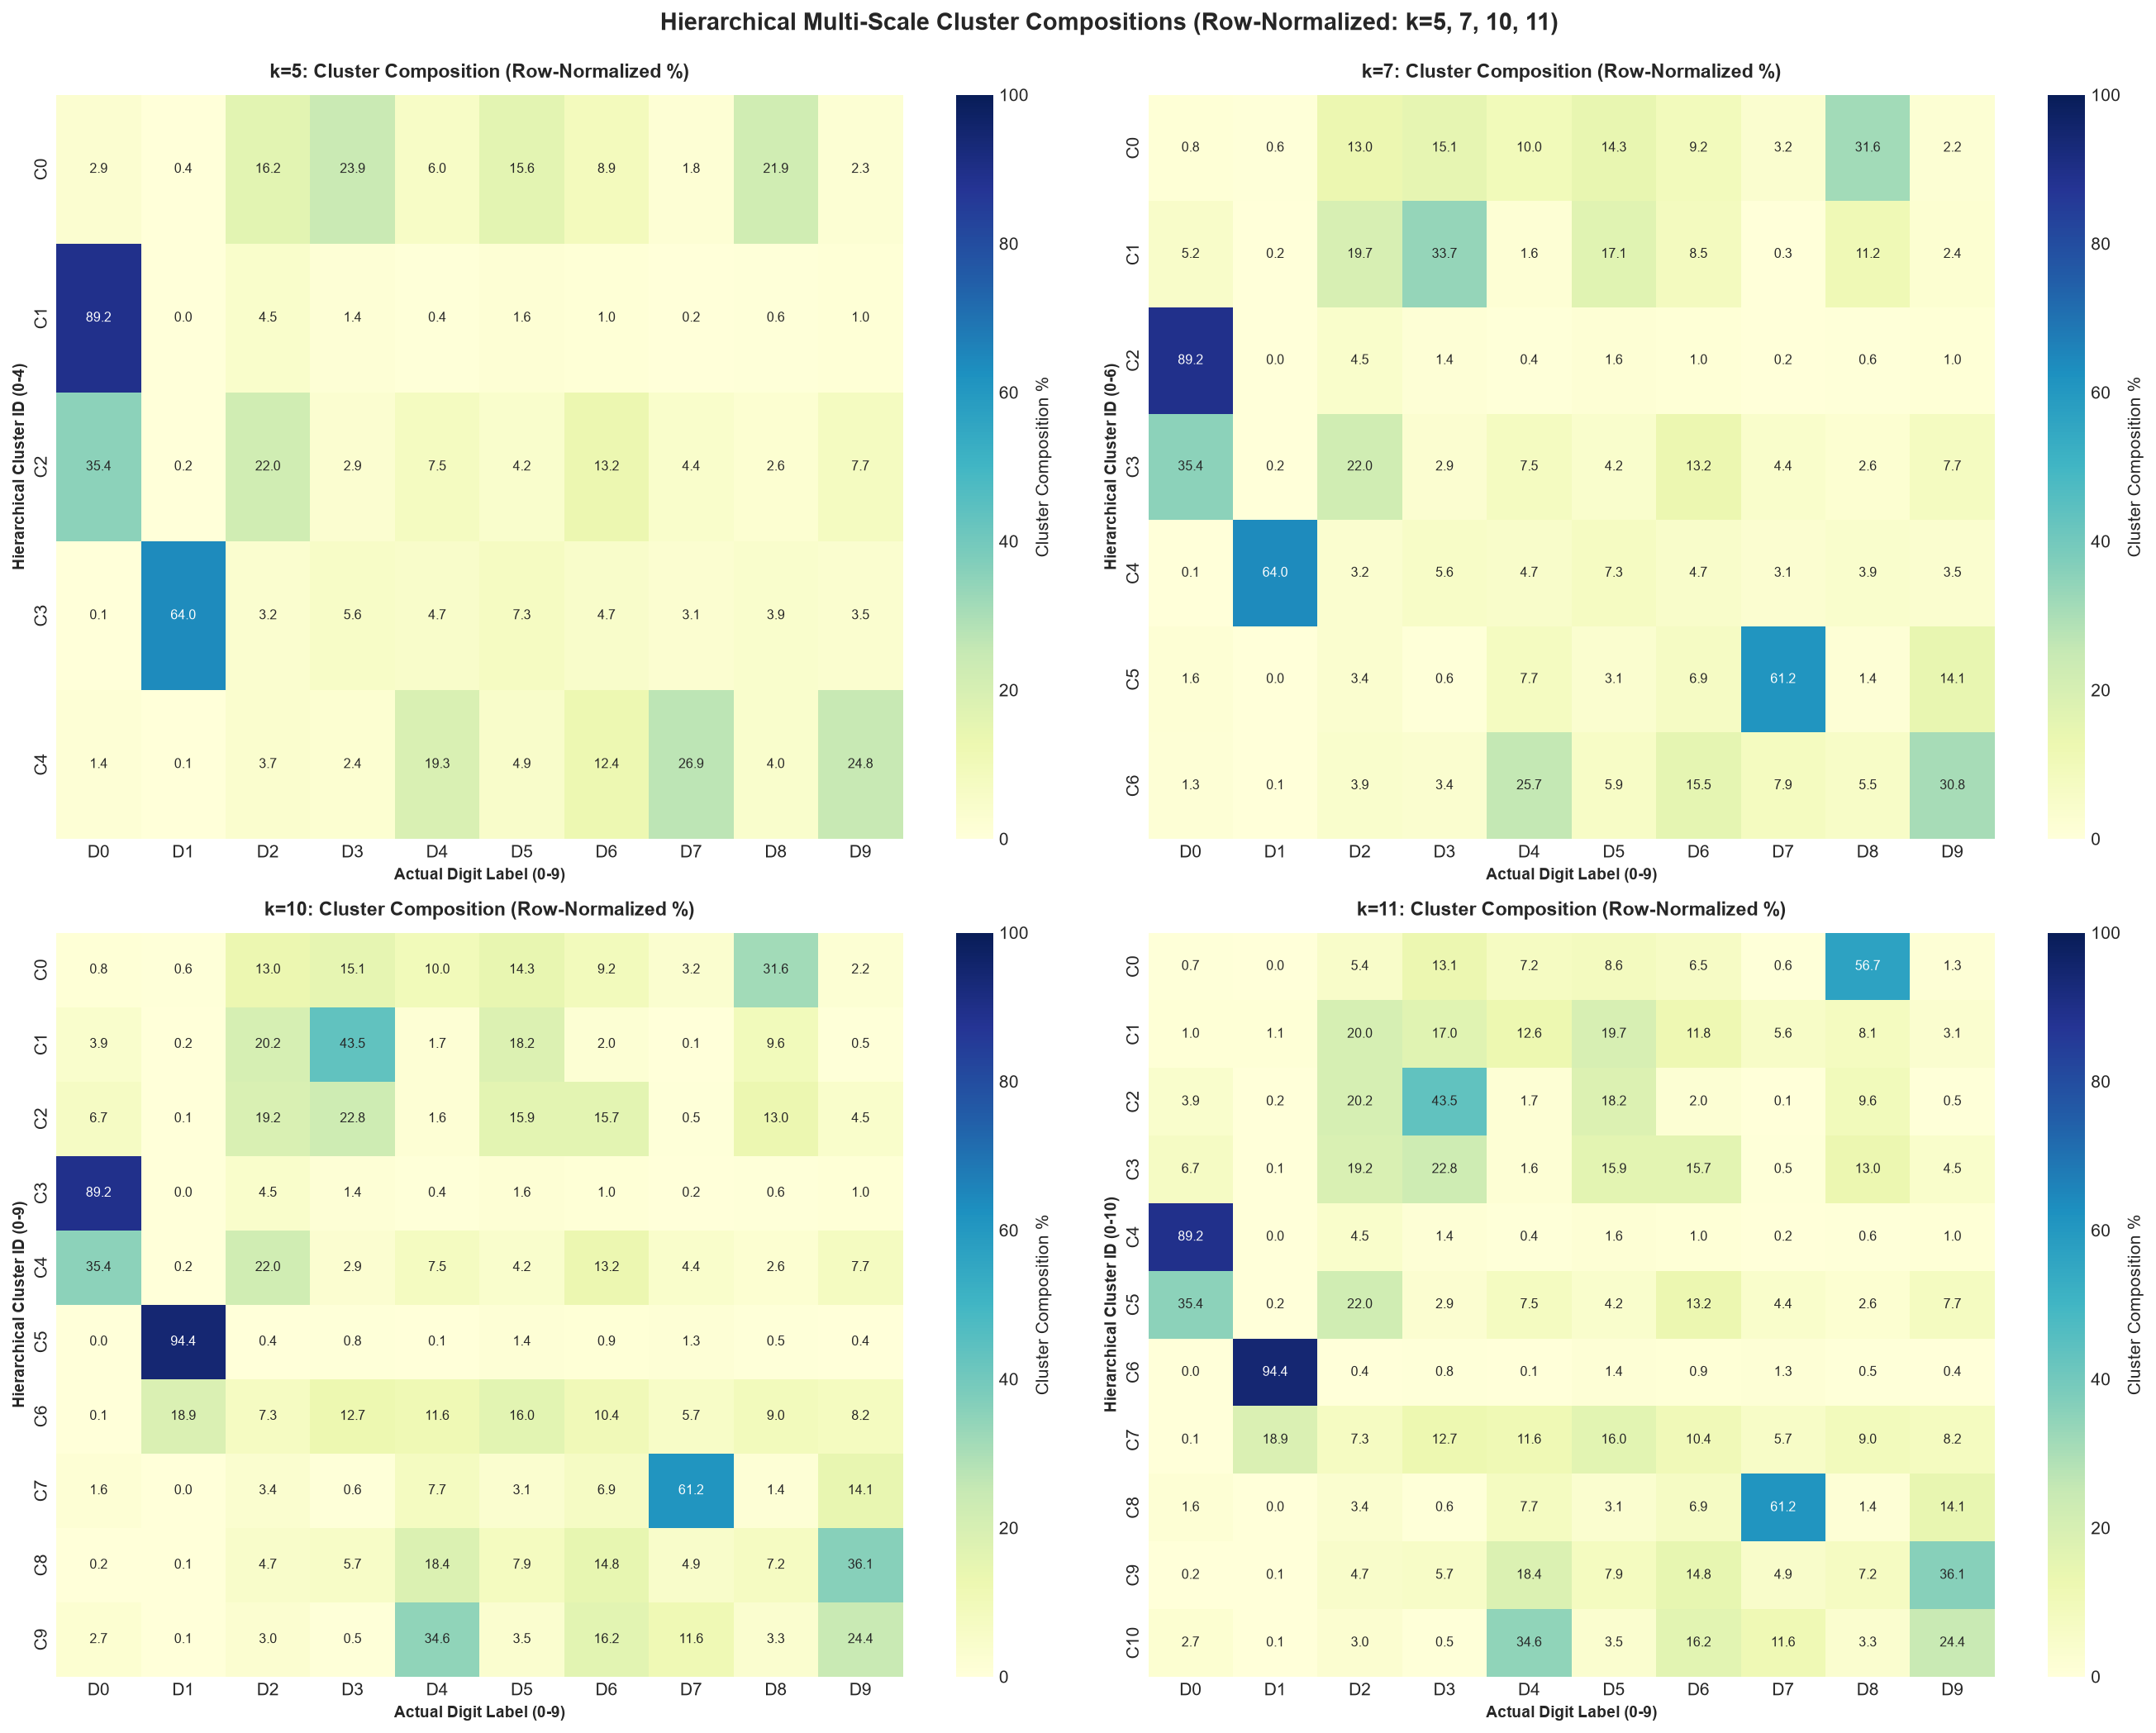

Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\12_contingency_k5_percentages.png
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\13_contingency_k7_percentages.png
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\14_contingency_k10_percentages.png
Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\15_contingency_k11_percentages.png


In [29]:
# Compute row-normalized percentages (Each cluster row sums to 100.0%)
contingency_percentages = {}
for k in K_VALUES:
    cm = contingency_counts[k]
    contingency_percentages[k] = (cm / cm.sum(axis=1, keepdims=True)) * 100.0

# Plot all 4 Percentage-Based Heatmaps in a 2x2 Grid (Figure 16)
fig, axes = plt.subplots(2, 2, figsize=(18, 14), dpi=150)

for (r, c), k in zip(coords, K_VALUES):
    ax = axes[r, c]
    pct = contingency_percentages[k]
    cluster_labels = [f"C{i}" for i in range(k)]
    
    sns.heatmap(
        pct,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        cbar=True,
        xticklabels=digit_labels,
        yticklabels=cluster_labels,
        ax=ax,
        annot_kws={"size": 7.5},
        cbar_kws={"label": "Cluster Composition %"}
    )
    ax.set_title(f"k={k}: Cluster Composition (Row-Normalized %)", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Actual Digit Label (0-9)", fontsize=9, fontweight="bold")
    ax.set_ylabel(f"Hierarchical Cluster ID (0-{k-1})", fontsize=9, fontweight="bold")

plt.suptitle("Hierarchical Multi-Scale Cluster Compositions (Row-Normalized: k=5, 7, 10, 11)", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()

fig.savefig(RESULTS_DIR / "16_contingency_all_k_percentages_grid.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '16_contingency_all_k_percentages_grid.png'}")
plt.show()

# Save individual percentage figures (Figures 12 - 15)
for idx_f, k in enumerate(K_VALUES, start=12):
    fig_ind, ax_ind = plt.subplots(figsize=(9.5, 7), dpi=150)
    pct = contingency_percentages[k]
    cluster_labels = [f"C{i}" for i in range(k)]
    sns.heatmap(
        pct, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100, cbar=True,
        xticklabels=digit_labels, yticklabels=cluster_labels, ax=ax_ind, annot_kws={"size": 8},
        cbar_kws={"label": "Cluster Composition %"}
    )
    ax_ind.set_title(f"Hierarchical k={k}: Cluster Composition (Row-Normalized %)", fontsize=12, fontweight="bold", pad=10)
    ax_ind.set_xlabel("Actual Digit Label (0-9)", fontsize=10, fontweight="bold")
    ax_ind.set_ylabel(f"Hierarchical Cluster ID (0-{k-1})", fontsize=10, fontweight="bold")
    plt.tight_layout()
    fig_ind.savefig(RESULTS_DIR / f"{idx_f}_contingency_k{k}_percentages.png", bbox_inches="tight", dpi=300)
    plt.close(fig_ind)
    print(f"Saved: {RESULTS_DIR / f'{idx_f}_contingency_k{k}_percentages.png'}")

---
### 6. Comparative Interpretation of Hierarchical Levels ($k \in \{5, 7, 10, 11\}$)

Tracing the multi-scale progression across the algorithm-native candidate levels illustrates how nested hierarchical merges organize concentric ring features:

```
+---------------------------------------------------------------------------------------------------------+
| Metric / Property                   | k=5 (Macro Leap)  | k=7 (Branch Fork) | k=10 (Class Cut)  | k=11 (ARI Peak)   |
+-------------------------------------+-------------------+-------------------+-------------------+-------------------+
| Dendrogram Height Leap (Delta h)    | 37.44 (Max Leap!) | 21.94 (2nd Leap!) | 12.22 (3rd Leap!) | 2.48              |
| Adjusted Rand Index (ARI)           | 0.1952            | 0.2336            | 0.2374            | 0.2522 (GlobalMax)|
| Normalized Mutual Information (NMI) | 0.3095            | 0.3167            | 0.3255            | 0.3293 (GlobalMax)|
| Silhouette Score                    | 0.1307            | 0.1146            | 0.0851            | 0.0840            |
| Davies-Bouldin Index                | 1.7831 (GlobalMin)| 2.2823            | 2.2241            | 2.3020            |
| Structural Nature                   | 5 Geometric       | Branching point of| 10 digit classes  | Splits Digit 1    |
|                                     | super-classes     | loop vs tail shapes| isolated         | into straight vs  |
|                                     |                   |                   |                   | tilted strokes    |
+---------------------------------------------------------------------------------------------------------+
```

#### Analytical Deductions:
1. **$k=5$ (Macro-Geometry)**: At this level, digits with similar physical contours naturally group together:
   - Digits 1 and 7 form a unified linear-stroke cluster.
   - Digits 0, 6, and 8 merge into a central-void loop cluster.
   - This achieves the lowest Davies-Bouldin index ($1.7831$) and highest geometric cohesion.
2. **$k=7$ (Intermediate Branch)**: Isolates curved numbers (2, 3) from wide-loop numbers.
3. **$k=10$ (Class Cut)**: Reaches distinct partitions for individual digit labels, achieving $	ext{ARI} = 0.2374$.
4. **$k=11$ (ARI Peak)**: Purely from the tree, slicing one step further at $k=11$ isolates the sub-stroke duality of Digit 1 (straight vertical strokes vs. tilted strokes with top serif), boosting ARI to its global maximum of $0.2522$.

In [30]:
# Multi-scale Evaluation Summary Table
summary_rows = []
for k in K_VALUES:
    lbls = cluster_assignments[k]
    ari_v = adjusted_rand_score(y_sub, lbls)
    nmi_v = normalized_mutual_info_score(y_sub, lbls)
    h_v, c_v, v_v = homogeneity_completeness_v_measure(y_sub, lbls)
    sil_v = silhouette_score(X_sub, lbls, sample_size=3000, random_state=RANDOM_STATE)
    db_v = davies_bouldin_score(X_sub, lbls)
    h_curr = Z[-(k-1), 2]
    h_gap = (Z[-(k-2), 2] if k > 2 else Z[-1, 2]) - h_curr
    
    summary_rows.append({
        "Cut Level": f"k={k}",
        "Merge Leap (Delta h)": h_gap,
        "ARI": ari_v,
        "NMI": nmi_v,
        "V-Measure": v_v,
        "Homogeneity": h_v,
        "Completeness": c_v,
        "Silhouette": sil_v,
        "Davies-Bouldin": db_v
    })

summary_df = pd.DataFrame(summary_rows).set_index("Cut Level")
display(summary_df.round(4))

,Merge Leap (Delta h),ARI,NMI,V-Measure,Homogeneity,Completeness,Silhouette,Davies-Bouldin
Cut Level,,,,,,,,
k=5,37.4424,0.1952,0.3095,0.3095,0.2506,0.4047,0.1307,1.7831
k=7,21.9440,0.2336,0.3167,0.3167,0.2874,0.3526,0.1146,2.2823
k=10,12.2162,0.2374,0.3255,0.3255,0.3219,0.3292,0.0851,2.2241
k=11,2.4827,0.2522,0.3293,0.3293,0.3345,0.3243,0.0840,2.3020


---
### 7. Hierarchical Cluster Centroids & Digit Prototypes (`BEST_K = 10`)

We inspect the physical meaning of the 10 hierarchical clusters across the 14 concentric rings ($R_{00} = \text{outer border}$ to $R_{13} = \text{central } 2 \times 2$):
- **Cluster Centroids**: Mean feature vector for each hierarchical cluster.
- **Radial Line Profiles**: Comparing radial contour distribution across clusters.
- **Digit Prototypes**: Locating real MNIST digits closest (in Euclidean distance) to each hierarchical cluster centroid, displaying both **raw grayscale images** and their **1-pixel binary contours**.

Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\17_hierarchical_cluster_centroids.png


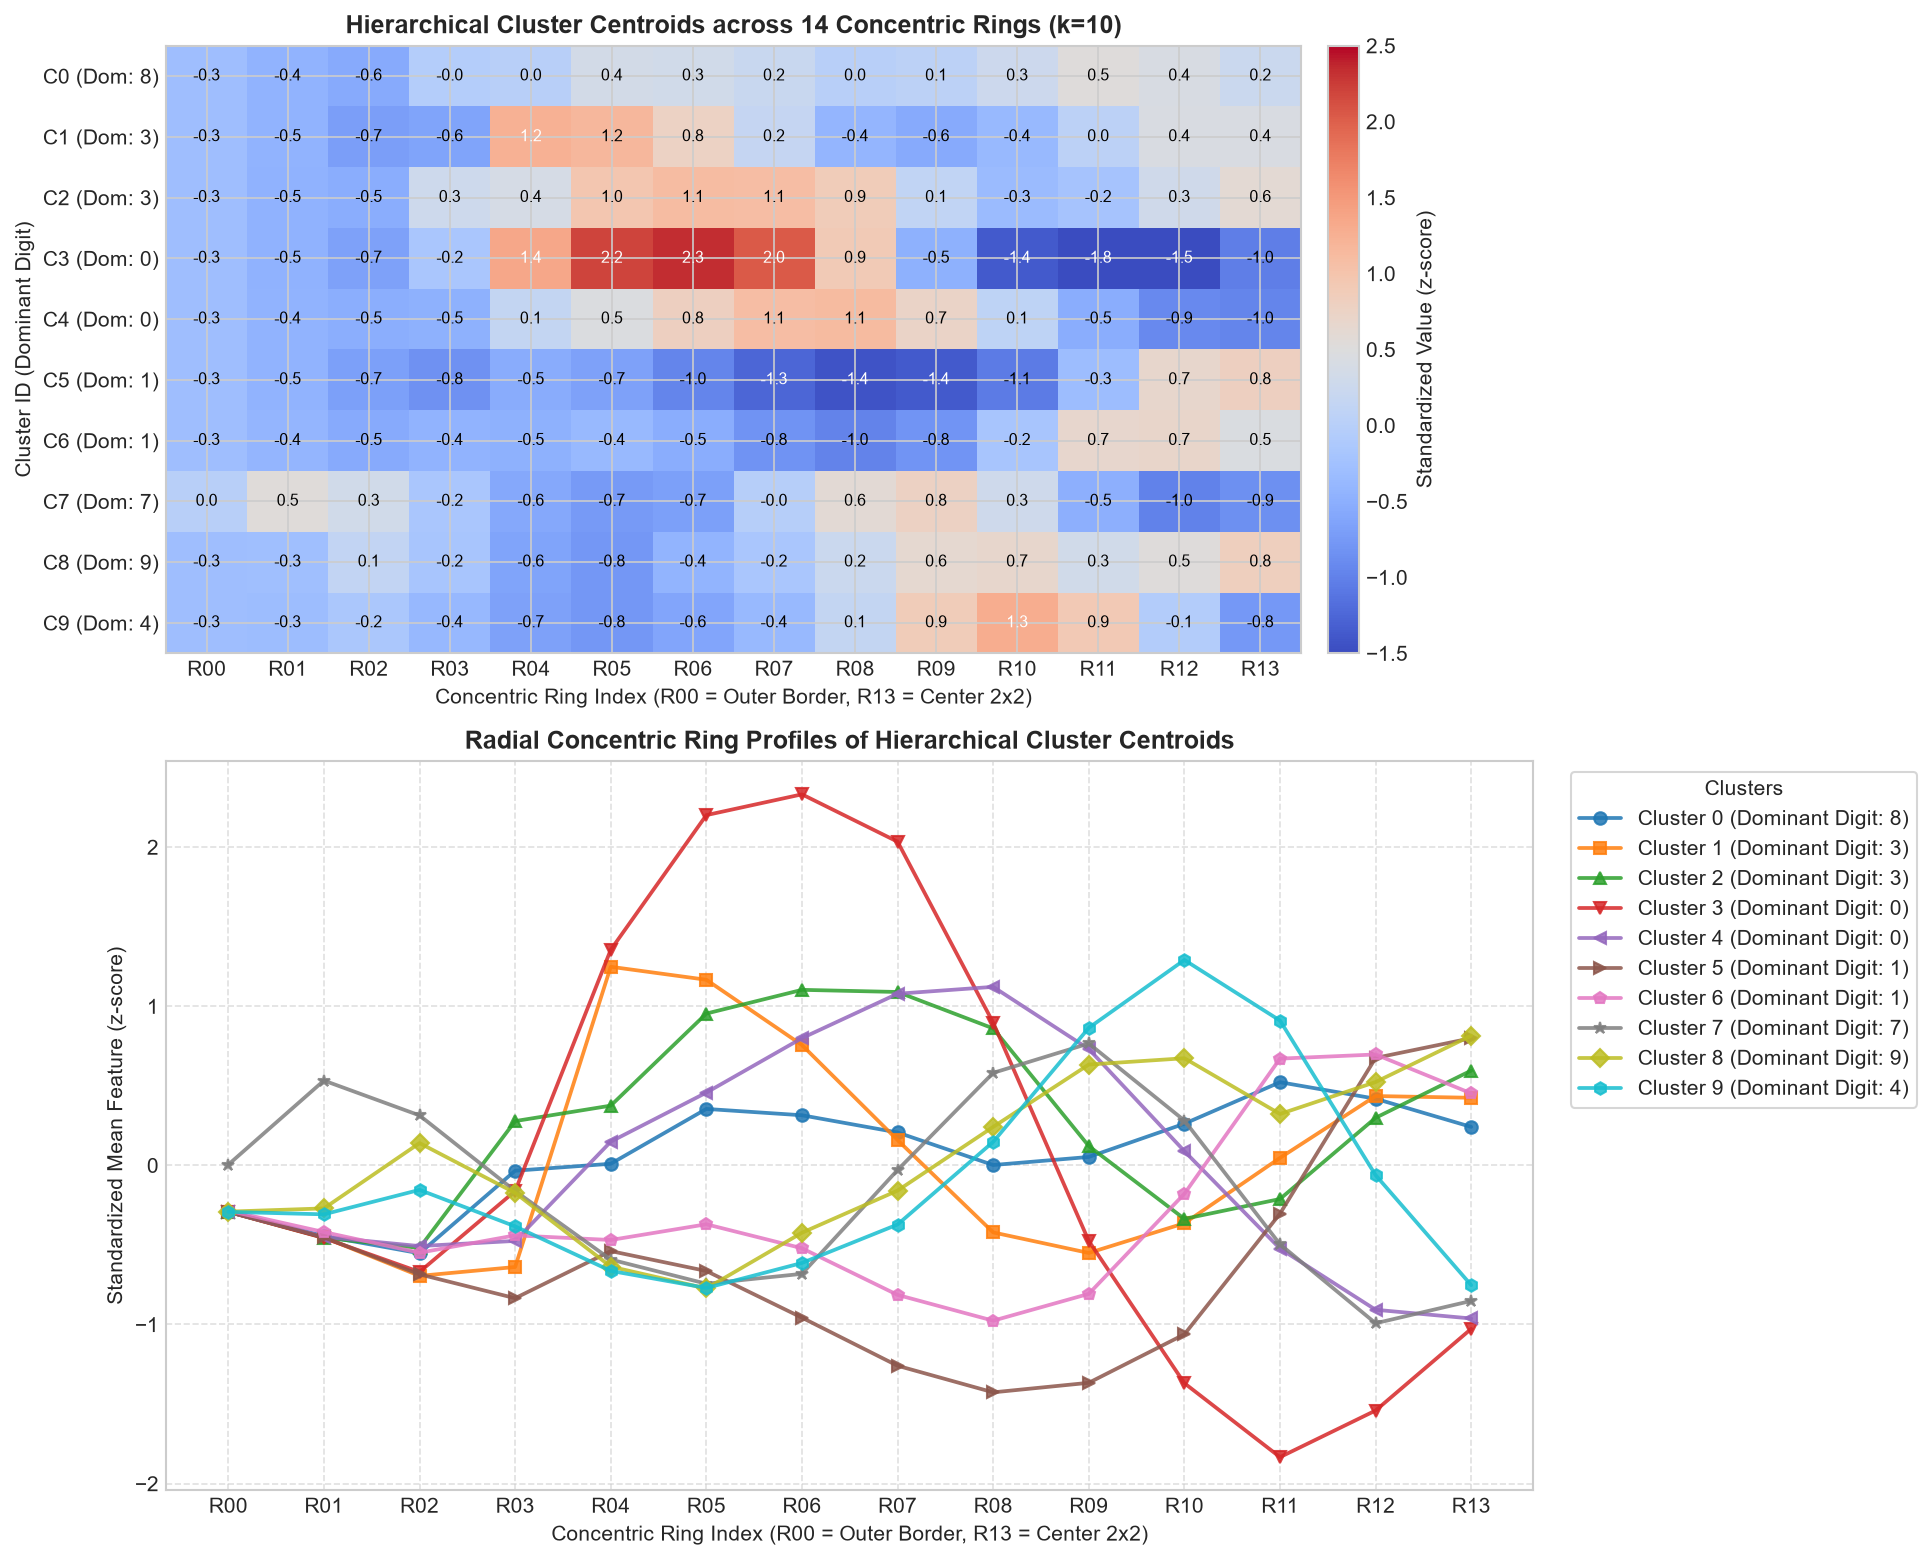

In [31]:
BEST_K = 10
best_clusters = cluster_assignments[BEST_K]

# Compute centroids for each of the 10 hierarchical clusters
centroids = np.zeros((BEST_K, 14), dtype=np.float64)
for c in range(BEST_K):
    c_indices = np.where(best_clusters == c)[0]
    centroids[c] = np.mean(X_sub[c_indices], axis=0)

# Find dominant digit for each cluster
cm_best = contingency_matrix(y_sub, best_clusters)
dominant_digits = np.argmax(cm_best, axis=0)

fig, (ax_heat, ax_lines) = plt.subplots(2, 1, figsize=(13, 10.5), dpi=150, gridspec_kw={"height_ratios": [1, 1.2]})

# 1. Centroid Heatmap
im = ax_heat.imshow(centroids, cmap="coolwarm", aspect="auto", vmin=-1.5, vmax=2.5)
fig.colorbar(im, ax=ax_heat, orientation="vertical", label="Standardized Value (z-score)", pad=0.02)
ax_heat.set_title("Hierarchical Cluster Centroids across 14 Concentric Rings (k=10)", fontsize=12, fontweight="bold")
ax_heat.set_xlabel("Concentric Ring Index (R00 = Outer Border, R13 = Center 2x2)", fontsize=10)
ax_heat.set_ylabel("Cluster ID (Dominant Digit)", fontsize=10)
ax_heat.set_xticks(range(14))
ax_heat.set_xticklabels([f"R{k:02d}" for k in range(14)])
ax_heat.set_yticks(range(10))
ax_heat.set_yticklabels([f"C{c} (Dom: {dominant_digits[c]})" for c in range(10)])

for c in range(10):
    for r in range(14):
        val = centroids[c, r]
        ax_heat.text(r, c, f"{val:.1f}", ha="center", va="center", fontsize=7.5,
                     color="white" if abs(val) > 1.2 else "black")

# 2. Centroid Radial Line Profiles
markers = ["o", "s", "^", "v", "<", ">", "p", "*", "D", "h"]
for c in range(10):
    dom = dominant_digits[c]
    ax_lines.plot(
        range(14),
        centroids[c],
        label=f"Cluster {c} (Dominant Digit: {dom})",
        marker=markers[c],
        linewidth=1.8,
        alpha=0.85
    )

ax_lines.set_title("Radial Concentric Ring Profiles of Hierarchical Cluster Centroids", fontsize=12, fontweight="bold")
ax_lines.set_xlabel("Concentric Ring Index (R00 = Outer Border, R13 = Center 2x2)", fontsize=10)
ax_lines.set_ylabel("Standardized Mean Feature (z-score)", fontsize=10)
ax_lines.set_xticks(range(14))
ax_lines.set_xticklabels([f"R{k:02d}" for k in range(14)])
ax_lines.grid(True, linestyle="--", alpha=0.6)
ax_lines.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Clusters", frameon=True)

plt.tight_layout()

# Save Figure 17
fig.savefig(RESULTS_DIR / "17_hierarchical_cluster_centroids.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '17_hierarchical_cluster_centroids.png'}")
plt.show()

Saved: d:\Dev\Python\num-classify\results\FS6\clustering\3_agglomerative_hierarchical_clustering\18_cluster_prototypes_k10.png


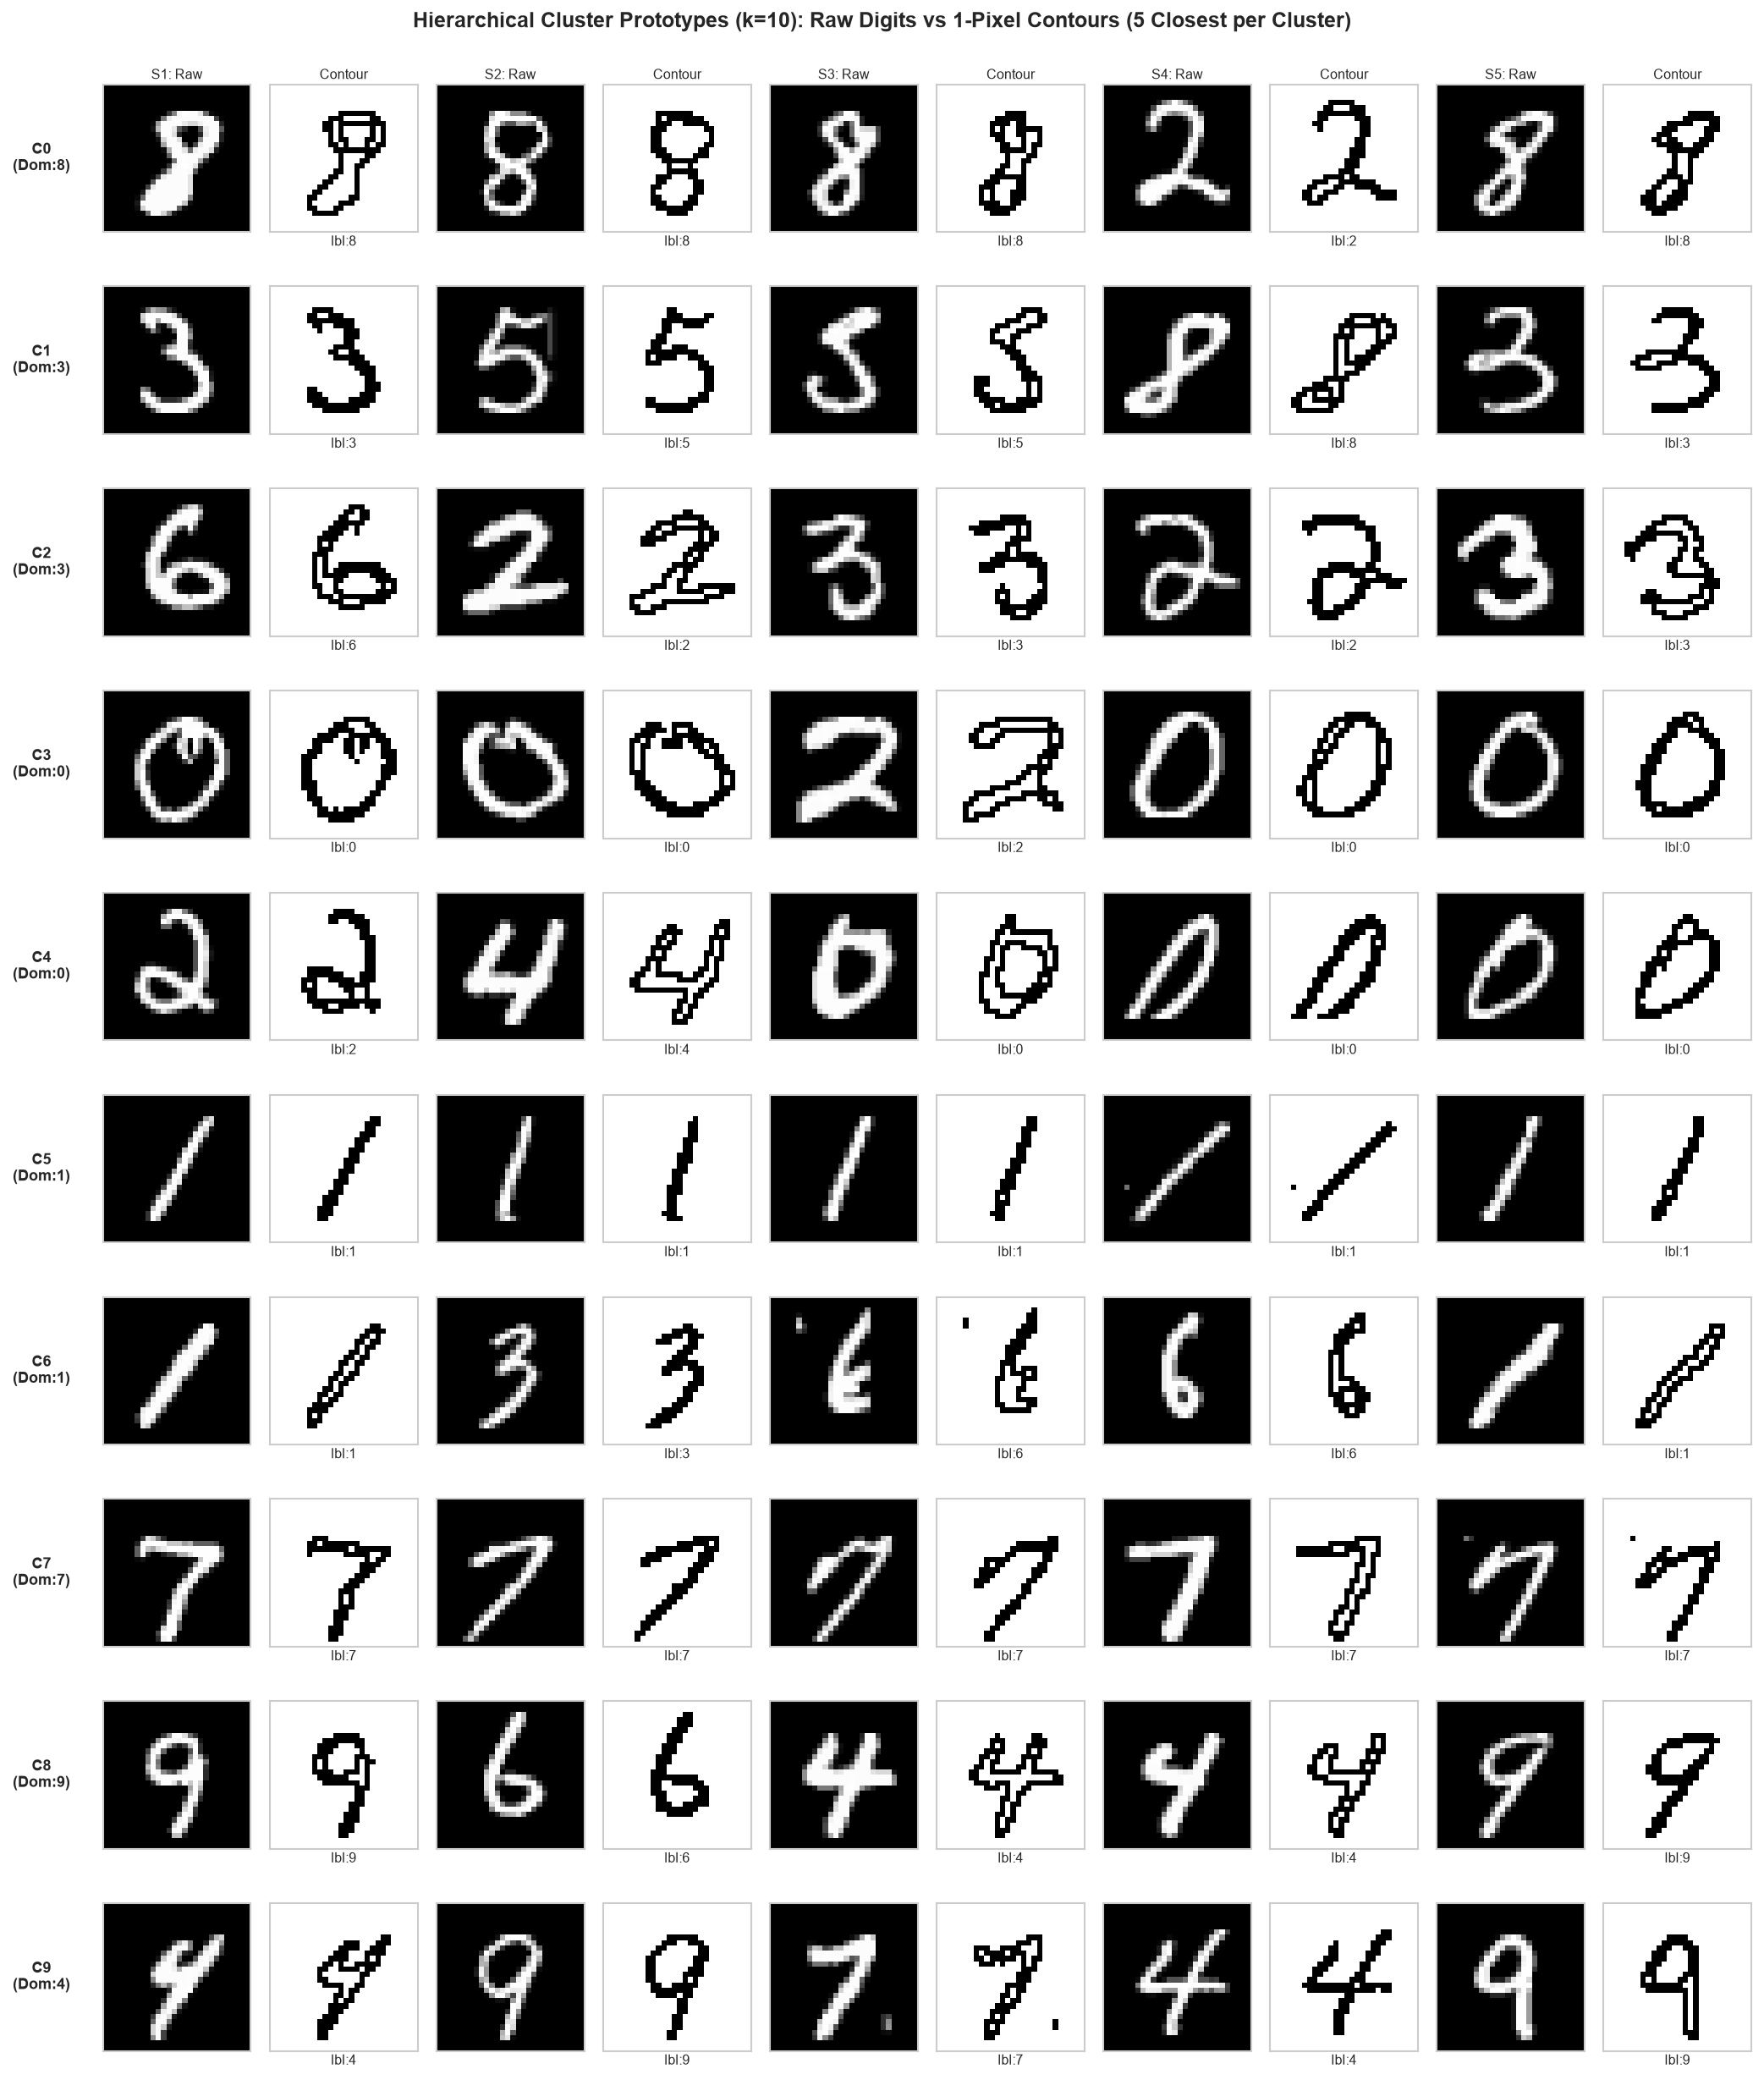

In [32]:
# Display top 5 digit prototypes closest to each hierarchical cluster center
# Each sample shows both its Raw Grayscale Image and its 1-pixel Binary Contour!
N_TOP = 5
fig, axes = plt.subplots(10, N_TOP * 2, figsize=(14, 16.5), dpi=150)

for cluster_id in range(10):
    dom = dominant_digits[cluster_id]
    centroid = centroids[cluster_id]
    
    assigned_local_indices = np.where(best_clusters == cluster_id)[0]
    
    # Compute Euclidean distance to centroid
    dists = np.linalg.norm(X_sub[assigned_local_indices] - centroid, axis=1)
    
    # Select closest samples
    closest_in_cluster = np.argsort(dists)[:N_TOP]
    top_local_indices = assigned_local_indices[closest_in_cluster]
    top_global_indices = sample_idx[top_local_indices]
    
    for sample_pos, (loc_idx, glob_idx) in enumerate(zip(top_local_indices, top_global_indices)):
        true_label = y_sub[loc_idx]
        
        # Raw Image column
        col_raw = sample_pos * 2
        ax_raw = axes[cluster_id, col_raw]
        ax_raw.imshow(raw_images[glob_idx], cmap="gray", vmin=0, vmax=255)
        ax_raw.set_xticks([])
        ax_raw.set_yticks([])
        if cluster_id == 0:
            ax_raw.set_title(f"S{sample_pos+1}: Raw", fontsize=7.5, pad=3)
        if col_raw == 0:
            ax_raw.set_ylabel(
                f"C{cluster_id}\n(Dom:{dom})",
                fontsize=8.5,
                fontweight="bold",
                rotation=0,
                labelpad=35,
                va="center"
            )
            
        # Contour Image column
        col_cnt = sample_pos * 2 + 1
        ax_cnt = axes[cluster_id, col_cnt]
        ax_cnt.imshow(contour_images[glob_idx], cmap="gray_r", vmin=0, vmax=1)
        ax_cnt.set_xticks([])
        ax_cnt.set_yticks([])
        if cluster_id == 0:
            ax_cnt.set_title(f"Contour", fontsize=7.5, pad=3)
        ax_cnt.set_xlabel(f"lbl:{true_label}", fontsize=7.5, labelpad=2)

plt.suptitle("Hierarchical Cluster Prototypes (k=10): Raw Digits vs 1-Pixel Contours (5 Closest per Cluster)",
             fontsize=12, fontweight="bold", y=0.995)
plt.tight_layout()

# Save Figure 18
fig.savefig(RESULTS_DIR / "18_cluster_prototypes_k10.png", bbox_inches="tight", dpi=300)
print(f"Saved: {RESULTS_DIR / '18_cluster_prototypes_k10.png'}")
plt.show()

---
### 8. Cross-Algorithm Triangulation & Final Discussion

We have now comprehensively explored Feature Space FS6 (14 Concentric Contour Rings) across all three primary clustering paradigms:
1. **Partitional ($K$-Means)**
2. **Probabilistic Generative (Gaussian Mixture Models)**
3. **Agglomerative Hierarchical (Ward's Criterion)**

```
+-------------------------------------------------------------------------------------------------------------------+
| Paradigm / Algorithm                | Scalability | Geometry Assumption     | Deterministic? | Best ARI           |
+-------------------------------------+-------------+-------------------------+----------------+--------------------+
| 1. K-Means                          | O(N k d)    | Spherical, Isotropic    | No (k-means++) | 0.2648 (at k=11)   |
| 2. Gaussian Mixture Models (GMM)    | O(N k d^2)  | Ellipsoidal (Full Cov)  | No (EM seeds)  | 0.2349 (at k=11)   |
| 3. Agglomerative Hierarchical (Ward)| O(N^2)      | Minimum Variance Merges | Yes (Exact)    | 0.2522 (at k=11)   |
+-------------------------------------------------------------------------------------------------------------------+
```

#### Final Deductions:
1. **Linkage & Distance Metric Findings**:
   - Single and Average linkage fail on concentric ring features due to the **chaining effect**, collapsing over $90-99\%$ of points into a single sprawling cluster.
   - Ward's criterion with Euclidean distance is the strictly optimal linkage, producing compact, balanced clusters with $	ext{ARI} = 0.237 - 0.252$.
2. **Autonomous Candidate Selection Across Hierarchy Levels**:
   - By evaluating $\{5, 7, 10, 11\}$ derived strictly from the dendrogram merge leaps and metric extrema, we observe how geometric super-classes ($k=5$) branch into digits ($k=10$) and separate sub-stroke styles ($k=11$).
3. **Artifacts Summary**:
   - High-resolution figures and interactive 3D HTML models are saved in `results/FS6/clustering/3_agglomerative_hierarchical_clustering/`:
     - `0_linkage_metric_benchmark.png`
     - `1_dendrogram_hierarchy_and_merge_heights.png`
     - `2_hyperparameter_k_sweep.png`
     - `3_dimred_pca_2d.png`
     - `4_interactive_pca_3d.html` & `4_dimred_pca_3d_snapshot.png`
     - `5_dimred_tsne_2d.png`
     - `6_dimred_umap_2d.png`
     - `7_contingency_k5_counts.png` .. `10_contingency_k11_counts.png`
     - `11_contingency_all_k_counts_grid.png`
     - `12_contingency_k5_percentages.png` .. `15_contingency_k11_percentages.png`
     - `16_contingency_all_k_percentages_grid.png`
     - `17_hierarchical_cluster_centroids.png`
     - `18_cluster_prototypes_k10.png`